In [1]:
import hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal, interpolate, stats

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
PINK, BLUE, GREY, GREEN, BURG = "#A33573", "#2A7F9E", "#9AA0A6", "#1C7C54", "#4D1434"
plt.rcParams.update({"figure.dpi": 100, "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
                     "axes.titleweight": "bold", "legend.frameon": False})

def gain_db(sos, f, fs):
    """Câștigul (dB) unui filtru în secțiuni de ordinul doi la frecvența f (Hz)."""
    _, h = signal.sosfreqz(sos, worN=[f], fs=fs)
    return float(20 * np.log10(np.abs(h[0]) + 1e-12))

def prf(flag, truth):
    """Precizie, recall, F1 ale unei detecții booleene față de un adevăr boolean."""
    flag, truth = np.asarray(flag, bool), np.asarray(truth, bool)
    tp = int((flag & truth).sum()); fp_ = int((flag & ~truth).sum()); fn = int((~flag & truth).sum())
    p = tp / (tp + fp_) if tp + fp_ else 0.0; r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

def _norm(v):
    if isinstance(v, (bool, np.bool_)): return str(bool(v))
    if isinstance(v, (int, float, np.integer, np.floating)): return f"{float(v):.2f}"
    return str(v)

def check(label, condition, hint=""):
    """Autoverificare: bifă verde dacă condiția este îndeplinită, altfel un indiciu. Nu modificați."""
    print(("✅ " if condition else "❌ ") + label + ("" if condition else f"   → indiciu: {hint}"))

def check_value(label, value, code, hint=""):
    """Compară valoarea voastră (numerele rotunjite la 2 zecimale) cu o amprentă a valorii așteptate."""
    ok = hashlib.sha256(_norm(value).encode()).hexdigest()[:8] == code
    print(("✅ " if ok else "❌ ") + label + ("" if ok else f"   → indiciu: {hint}"))


# Laboratorul 4 — Exemple rezolvate
**Sisteme bazate pe cunoștințe · Pre-procesarea datelor II: filtre, eliminarea tendinței, interpolare, valori aberante, reducerea dimensionalității și puncte de schimbare**

Laboratorul 3 a *diagnosticat* datele (calitate, tendință, sezonalitate, spectru). Aici le **tratăm**. Pentru fiecare metodă facem trei lucruri:

1. **Cum o proiectăm** – ce parametri există și cum îl alegem pe fiecare *din date*, nu prin încercări la întâmplare;
2. **Un exemplu sintetic** al cărui adevăr îl cunoaștem, ca să vedem ce face fiecare parametru (și ce se întâmplă când este greșit);
3. **Un exemplu real** (puteri pe benzi EEG, trafic rutier orar, un birou inteligent) în care nu există adevăr cunoscut, ci doar raționamentul de la pasul 1.

Seturile de date din folderul caietului: `sleepy_driver_eeg_data.csv`, `Metro_Interstate_Traffic_Volume.csv`, `smart_office_dataset.csv`.

**Părți:** 1 Filtre · 2 Eliminarea tendinței · 3 Interpolare · 4 Valori aberante · 5 Reducerea dimensionalității · 6 Puncte de schimbare · 7 Un pipeline complet.

# Partea 1 — Cum proiectăm un filtru

Un filtru păstrează unele frecvențe și le atenuează pe altele. Înainte de a atinge orice funcție, răspundeți **în Hz**:

* *Ce vreau să păstrez?* (banda fenomenului: undele alfa 8–12 Hz, ciclul zilnic 1/24 cicluri pe oră…)
* *Ce vreau să elimin?* (rețeaua de 50 Hz, o derivă sub 0.5 Hz, zgomot peste 40 Hz…)
* *Cu ce frecvență este eșantionat semnalul?* Frecvența de eșantionare `fs` fixează cea mai mare frecvență utilizabilă, **fs / 2** (Nyquist).

Răspunsurile dau **tipul filtrului** (trece-jos, trece-sus, trece-bandă, oprește-bandă/notch) și **frecvențele de tăiere**. Abia apoi alegem **familia** (medie mobilă, Butterworth, FIR, median, Savitzky–Golay) și **ordinul / lungimea**.

## 1.1 · Un semnal sintetic de tip EEG (știm tot ce conține)

Frecvența de eșantionare `fs = 250 Hz`, 10 secunde. Semnalul conține: un **ritm alfa de 10 Hz** (ce ne dorim), o **derivă lentă** de 0.3 Hz, **interferență de rețea** la 50 Hz, zgomot alb și câteva vârfuri de un eșantion (artefacte de electrod).

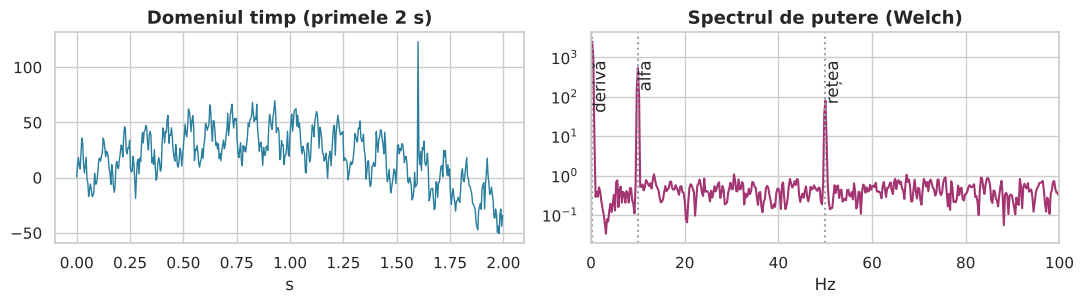

In [2]:
fs = 250
t = np.arange(0, 10, 1 / fs)
rng = np.random.default_rng(0)

alpha  = 20 * np.sin(2 * np.pi * 10 * t)
drift  = 40 * np.sin(2 * np.pi * 0.3 * t)
mains  = 8  * np.sin(2 * np.pi * 50 * t)
noise  = 5  * rng.normal(size=t.size)
spikes = np.zeros_like(t); spikes[[400, 1100, 1900]] = [120, -150, 100]

x = alpha + drift + mains + noise + spikes          # ce furnizează amplificatorul

f, Pxx = signal.welch(x, fs=fs, nperseg=1024)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(t[:500], x[:500], color=BLUE, lw=1); ax[0].set(title="Domeniul timp (primele 2 s)", xlabel="s")
ax[1].semilogy(f, Pxx, color=PINK); ax[1].set(title="Spectrul de putere (Welch)", xlabel="Hz", xlim=(0, 100))
for fx, name in [(0.3, "derivă"), (10, "alfa"), (50, "rețea")]:
    ax[1].axvline(fx, color=GREY, ls=":"); ax[1].text(fx, Pxx.max() / 3, name, rotation=90, va="top")
plt.tight_layout(); plt.show()

**Citirea spectrului este primul pas al proiectării**: trei vârfuri (0.3, 10 și 50 Hz) și un prag plat de zgomot. Banda dorită (10 Hz) se află **între** derivă și rețea, deci un **trece-bandă 5–30 Hz** le elimină pe amândouă deodată; un **trece-sus** singur ar lăsa rețeaua; un **notch** singur ar lăsa deriva.

## 1.2 · Cele patru tipuri clasice de filtre: trece-jos, trece-sus, trece-bandă, oprește-bandă

Orice filtru din acest laborator este de **unul dintre cele patru tipuri**, definite de partea din spectru pe care o lasă să treacă. Partea păstrată este **banda de trecere**, partea respinsă este **banda de oprire**, iar între ele se află **banda de tranziție**, în care câștigul scade de la „păstrat” la „respins”. Un filtru real nu poate avea o margine verticală: cu cât cereți o bandă de tranziție mai îngustă, cu atât plătiți un **ordin mai mare** (sau un FIR mai lung).

| Tip | Păstrează (banda de trecere) | Respinge (banda de oprire) | Frecvența (frecvențele) de tăiere | Utilizare tipică |
|---|---|---|---|---|
| **Trece-jos** | sub `fc` | peste `fc` | una: `fc` | netezire, eliminarea zgomotului, anti-aliasing, componenta lentă a unei serii |
| **Trece-sus** | peste `fc` | sub `fc` | una: `fc` | eliminarea derivei sau a liniei de bază (eliminarea tendinței, Partea 2) |
| **Trece-bandă** | între `f1` și `f2` | sub `f1` și peste `f2` | două: `[f1, f2]` | izolarea unui ritm: alfa 8–12 Hz, ciclul zilnic al traficului |
| **Oprește-bandă** (notch) | tot, în afară de `[f1, f2]` | între `f1` și `f2` | două: `[f1, f2]` | eliminarea unei interferențe: rețeaua de 50 Hz |

**Vocabularul unei specificații.** **Frecvența de tăiere** `fc` este locul unde câștigul a scăzut cu 3 dB (la 71 % din amplitudine) – pentru Butterworth, mijlocul tranziției. În `buttord(wp, ws, gpass, gstop)` descrieți filtrul prin cele două margini de bandă: `wp` = marginea **benzii de trecere**, `ws` = marginea **benzii de oprire**, `gpass` = pierderea maximă tolerată în banda de trecere (dB), `gstop` = atenuarea minimă cerută în banda de oprire (dB). Ordinea celor două margini spune tipul: trece-jos `wp < ws`, trece-sus `wp > ws`; pentru tipurile de bandă, `wp` și `ws` sunt liste cu două elemente, iar la un trece-bandă banda de trecere se află *în interiorul* marginilor benzii de oprire, la un oprește-bandă invers.

**Cum alegeți tipul: desenați spectrul, apoi întrebați ce se află *sub*, *între* și *deasupra* frecvențelor dorite.** Componentă dorită fără nimic dorit deasupra ei → trece-jos; nimic dorit dedesubt → trece-sus; nedorit de ambele părți → trece-bandă; o singură linie îngustă nedorită → oprește-bandă.

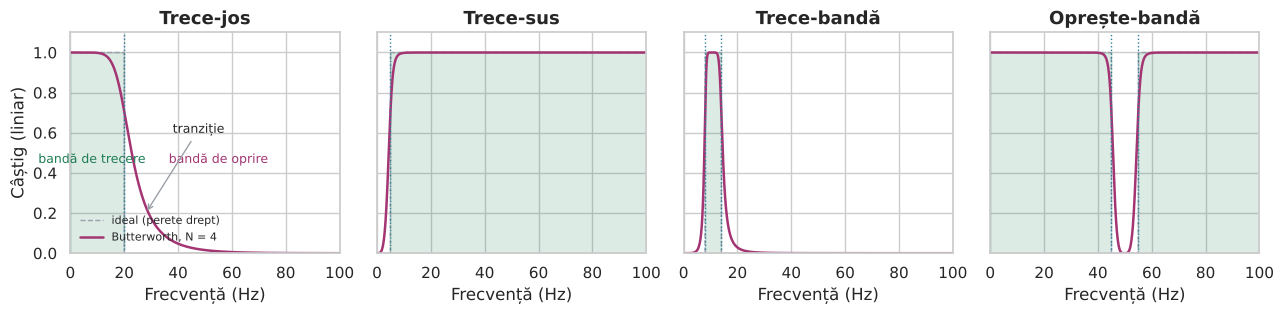

In [3]:
fs = 250
panels = [("Trece-jos",  "low",      20,        [(0, 20), (45, 125)]),
          ("Trece-sus", "highpass", 5,         [(0, 2), (12, 125)]),
          ("Trece-bandă", "bandpass", [8, 14],   [(0, 4), (20, 125)]),
          ("Oprește-bandă", "bandstop", [45, 55],  [(0, 40), (60, 125)])]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
for ax, (name, btype, wn, _) in zip(axes, panels):
    sos = signal.butter(4, wn, btype, fs=fs, output="sos")
    freq, h = signal.sosfreqz(sos, worN=4000, fs=fs)
    ideal = np.zeros_like(freq)
    w = np.atleast_1d(wn)
    if btype == "low":        ideal[freq <= w[0]] = 1
    if btype == "highpass":   ideal[freq >= w[0]] = 1
    if btype == "bandpass":   ideal[(freq >= w[0]) & (freq <= w[1])] = 1
    if btype == "bandstop":   ideal[(freq < w[0]) | (freq > w[1])] = 1
    ax.fill_between(freq, 0, ideal, color=GREEN, alpha=0.15, step="mid")
    ax.plot(freq, ideal, color=GREY, ls="--", lw=1, label="ideal (perete drept)")
    ax.plot(freq, np.abs(h), color=PINK, lw=1.8, label="Butterworth, N = 4")
    for fc in w: ax.axvline(fc, color=BLUE, ls=":", lw=1)
    ax.set(title=name, xlabel="Frecvență (Hz)", xlim=(0, 100), ylim=(0, 1.1))
axes[0].set_ylabel("Câștig (liniar)"); axes[0].legend(fontsize=8, loc="lower left")
axes[0].text(8, 0.45, "bandă de trecere", color=GREEN, ha="center", fontsize=9)
axes[0].text(55, 0.45, "bandă de oprire", color=PINK, ha="center", fontsize=9)
axes[0].annotate("tranziție", xy=(28, 0.2), xytext=(38, 0.6), fontsize=9, arrowprops=dict(arrowstyle="->", color=GREY))
plt.tight_layout(); plt.show()

Liniile verticale punctate sunt frecvențele de tăiere. Zona verde este banda de trecere a filtrului **ideal**; filtrul real (roz) rotunjește colțul, iar lățimea acestei rotunjiri este banda de tranziție. Să aplicăm acum cele patru tipuri semnalului sintetic de la 1.1, care conține o **derivă de 0.3 Hz**, un **ritm alfa de 10 Hz** și o linie de **rețea de 50 Hz**, și să citim într-un tabel ce face fiecare filtru fiecărei componente:

                        derivă 0.3 Hz  alfa 10 Hz  rețea 50 Hz
trece-jos  fc = 20                0.0        -0.0        -36.1
trece-sus fc = 2                -65.9        -0.0         -0.0
trece-bandă [5, 30]            -103.8        -0.0        -25.4
oprește-bandă [45, 55]            0.0        -0.0       -135.2


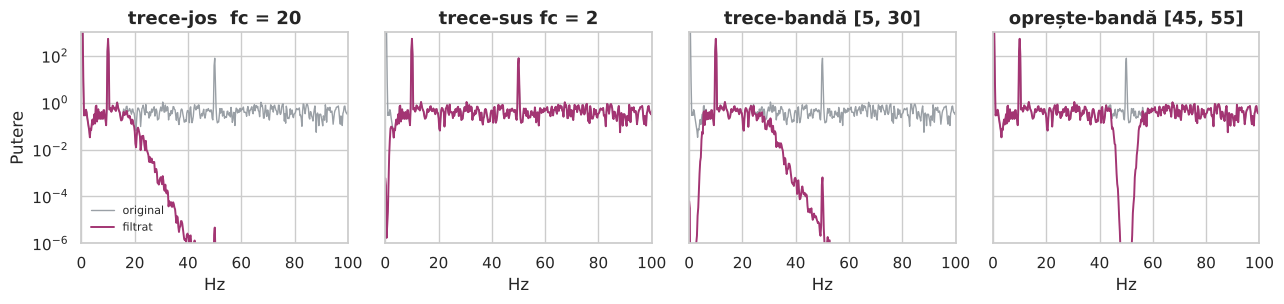

In [4]:
designs = {"trece-jos  fc = 20":       signal.butter(4, 20, btype="low", fs=fs, output="sos"),
           "trece-sus fc = 2":        signal.butter(4, 2, btype="high", fs=fs, output="sos"),
           "trece-bandă [5, 30]":       signal.butter(4, [5, 30], btype="bandpass", fs=fs, output="sos"),
           "oprește-bandă [45, 55]":      signal.butter(4, [45, 55], btype="bandstop", fs=fs, output="sos")}
rows = {name: [gain_db(s, f, fs) for f in (0.3, 10, 50)] for name, s in designs.items()}
print(pd.DataFrame(rows, index=["derivă 0.3 Hz", "alfa 10 Hz", "rețea 50 Hz"]).T.round(1).to_string())

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, (name, s) in zip(axes, designs.items()):
    ff, P0 = signal.welch(x, fs=fs, nperseg=1024)
    _, P1 = signal.welch(signal.sosfiltfilt(s, x), fs=fs, nperseg=1024)
    ax.semilogy(ff, P0, color=GREY, lw=1, label="original"); ax.semilogy(ff, P1, color=PINK, lw=1.4, label="filtrat")
    ax.set(title=name, xlabel="Hz", xlim=(0, 100), ylim=(1e-6, 1e3))
axes[0].set_ylabel("Putere"); axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

Câștigurile apropiate de 0 dB înseamnă „păstrat”, valorile negative mari înseamnă „respins”. Citind tabelul rând cu rând: **trece-josul** păstrează deriva și ritmul alfa, dar elimină rețeaua; **trece-susul** elimină doar deriva; **trece-bandă** păstrează doar ritmul alfa (le elimină pe ambele vecine deodată); **oprește-banda** elimină doar rețeaua și lasă restul neatins. Niciunul nu este „cel mai bun”: tipul rezultă din **ce se află de o parte și de alta a benzii dorite**, și abia apoi ne întrebăm cât de abruptă trebuie să fie tranziția.

## 1.3 · Cel mai simplu filtru trece-jos: media mobilă

O medie mobilă pe `w` eșantioane este un filtru al cărui **prim zero** se află la `fs / w`. Aceasta este întreaga regulă de proiectare: *alegeți `w` astfel încât primul zero să cadă pe frecvența pe care vreți să o eliminați.* Frecvența ei de tăiere (−3 dB) este aproximativ `0.44 · fs / w`. Este ieftină și nu produce depășiri, dar este un filtru slab: atenuarea peste frecvența de tăiere este lentă și are lobi laterali.

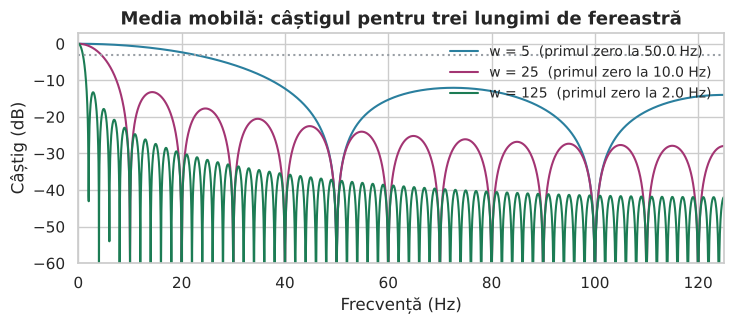

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for w, c in [(5, BLUE), (25, PINK), (125, GREEN)]:
    freq, h = signal.freqz(np.ones(w) / w, 1, worN=4096, fs=fs)
    ax.plot(freq, 20 * np.log10(np.abs(h) + 1e-6), color=c, label=f"w = {w}  (primul zero la {fs / w:.1f} Hz)")
ax.set(xlim=(0, 125), ylim=(-60, 3), xlabel="Frecvență (Hz)", ylabel="Câștig (dB)", title="Media mobilă: câștigul pentru trei lungimi de fereastră")
ax.axhline(-3, color=GREY, ls=":"); ax.legend(loc="upper right", fontsize=10); plt.tight_layout(); plt.show()

**Folosiți-o pentru a elimina o frecvență cunoscută.** Rețeaua de 50 Hz cu `fs = 250` dă `w = fs / 50 = 5` eșantioane: media pe exact o perioadă a rețelei este zero. O fereastră de 6 *nu* ar elimina-o. Prețul: ritmul alfa (10 Hz) este atenuat puțin și el (circa 0.6 dB), iar tot ce depășește ~20 Hz este redus doar slab, cu excepția zonelor din apropierea zerourilor.

In [6]:
w = int(fs / 50)
x_ma = np.convolve(x, np.ones(w) / w, mode="same")
print("fereastră:", w, "eșantioane")
print(f"câștig la 10 Hz (alfa): {20*np.log10(abs(signal.freqz(np.ones(w)/w, 1, worN=[10], fs=fs)[1][0])):.2f} dB")
print("câștig la 50 Hz (rețea): sub -100 dB (zero exact al răspunsului)")

fereastră: 5 eșantioane
câștig la 10 Hz (alfa): -0.56 dB
câștig la 50 Hz (rețea): sub -100 dB (zero exact al răspunsului)


## 1.4 · Butterworth: frecvența de tăiere, ordinul și de ce folosim întotdeauna `sos`

Filtrul Butterworth are **banda de trecere cea mai plată posibilă**. Are doi parametri de proiectare:

* **frecvența de tăiere** `fc` (Hz): locul unde câștigul este −3 dB. Pentru un trece-bandă sau oprește-bandă se dau două numere `[f_low, f_high]`;
* **ordinul** `N`: cu cât panta este mai abruptă, cu atât `N` este mai mare; atenuarea crește cu `20·N dB pe decadă`. Fiecare pas în `N` costă mai multă întârziere și un risc mai mare de probleme numerice.

Reguli de alegere: puneți `fc` **între** frecvența dorită și cea nedorită (mijlocul geometric este un bun început); apoi alegeți **cel mai mic `N`** care dă atenuarea necesară la frecvența nedorită. SciPy îl calculează: `signal.buttord(wp, ws, gpass, gstop, fs=fs)`, unde `wp` este sfârșitul benzii de trecere, `ws` începutul benzii de oprire, `gpass` pierderea maximă permisă în banda de trecere (dB) iar `gstop` atenuarea minimă în banda de oprire (dB).

Dați întotdeauna frecvența de eșantionare prin `fs=fs` (atunci frecvențele de tăiere sunt în Hz, nu normalizate) și cereți `output="sos"` (secțiuni de ordinul doi, stabile numeric).

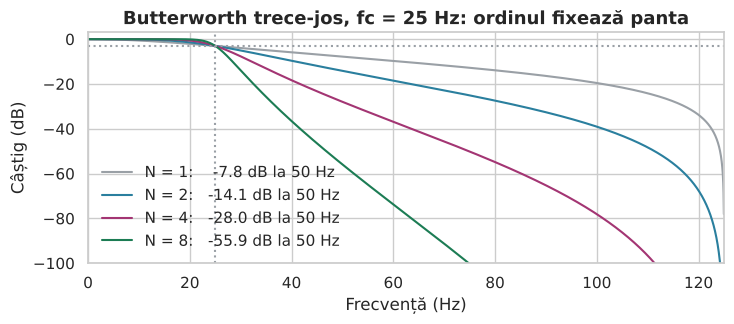

cel mai mic ordin: 5   frecvență de tăiere: 17.11 Hz


In [7]:
fc = 25                                           # între alfa (10 Hz) și rețea (50 Hz)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for N, c in zip([1, 2, 4, 8], [GREY, BLUE, PINK, GREEN]):
    sos = signal.butter(N, fc, btype="low", fs=fs, output="sos")
    freq, h = signal.sosfreqz(sos, worN=4096, fs=fs)
    ax.plot(freq, 20 * np.log10(np.abs(h) + 1e-9), color=c, label=f"N = {N}:  {gain_db(sos, 50, fs):6.1f} dB la 50 Hz")
ax.axvline(fc, color=GREY, ls=":"); ax.axhline(-3, color=GREY, ls=":")
ax.set(xlim=(0, 125), ylim=(-100, 3), xlabel="Frecvență (Hz)", ylabel="Câștig (dB)", title=f"Butterworth trece-jos, fc = {fc} Hz: ordinul fixează panta")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

# SciPy găsește cel mai mic ordin: bandă de trecere până la 15 Hz (<=1 dB pierdere), bandă de oprire de la 40 Hz (>=40 dB atenuare)
N_min, Wn = signal.buttord(wp=15, ws=40, gpass=1, gstop=40, fs=fs)
print("cel mai mic ordin:", N_min, "  frecvență de tăiere:", round(Wn, 2), "Hz")

**De ce `sos`?** Forma clasică `b, a` (polinoame la numărător/numitor) pierde precizie când frecvența de tăiere este foarte mică față de `fs` sau ordinul este mare. Filtrul devine atunci **instabil** (poli în afara cercului unitate), iar ieșirea explodează. Comparați:

In [8]:
# un trece-sus de 0.1 Hz la fs = 250 Hz, ordin 8: frecvența de tăiere este 1/1250 din frecvența de eșantionare
b, a = signal.butter(8, 0.1, btype="high", fs=fs, output="ba")
sos  = signal.butter(8, 0.1, btype="high", fs=fs, output="sos")
print("cea mai mare rază a polilor, forma b/a:", round(np.abs(np.roots(a)).max(), 4), "(>1 înseamnă instabil)")
y_ba  = signal.lfilter(b, a, x)
y_sos = signal.sosfilt(sos, x)
print("max |y|  forma b/a:", f"{np.abs(y_ba).max():.3g}", "   forma sos:", f"{np.abs(y_sos).max():.3g}")

cea mai mare rază a polilor, forma b/a: 1.0146 (>1 înseamnă instabil)
max |y|  forma b/a: 1.69e+16    forma sos: 174


## 1.5 · Trece-bandă și notch: proiectare pentru ritmul alfa

Pentru ritmul alfa vrem 8–12 Hz plus o marjă. Un trece-bandă **nu poate fi prea îngust pentru ordinul său**: o bandă foarte îngustă cere un ordin mare și este sensibilă la frecvența exactă. În practică: folosiți banda de interes cu o marjă (aici 5–30 Hz) și ordinul 4.

Pentru o singură frecvență perturbatoare este mai bun un filtru **notch**. Parametrul lui este **factorul de calitate** `Q = f0 / lățimea de bandă`: cu `Q = 30` notch-ul de la 50 Hz are doar 1.7 Hz lățime, cu `Q = 5` are 10 Hz și începe să consume semnalul din jur.

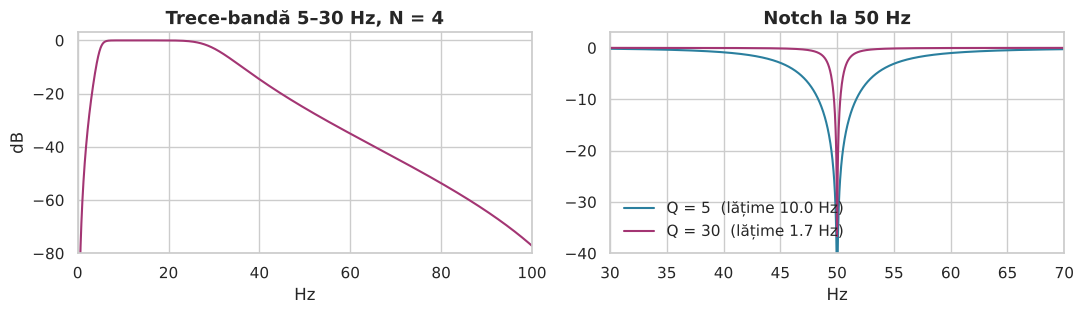

In [9]:
sos_bp = signal.butter(4, [5, 30], btype="bandpass", fs=fs, output="sos")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
freq, h = signal.sosfreqz(sos_bp, worN=4096, fs=fs)
ax[0].plot(freq, 20*np.log10(np.abs(h)+1e-9), color=PINK); ax[0].set(xlim=(0, 100), ylim=(-80, 3), title="Trece-bandă 5–30 Hz, N = 4", xlabel="Hz", ylabel="dB")
for Q, c in [(5, BLUE), (30, PINK)]:
    b, a = signal.iirnotch(50, Q, fs=fs)
    freq, h = signal.freqz(b, a, worN=4096, fs=fs)
    ax[1].plot(freq, 20*np.log10(np.abs(h)+1e-9), color=c, label=f"Q = {Q}  (lățime {50/Q:.1f} Hz)")
ax[1].set(xlim=(30, 70), ylim=(-40, 3), title="Notch la 50 Hz", xlabel="Hz"); ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

## 1.6 · Cauzal sau cu fază zero? `sosfilt` față de `sosfiltfilt`

Un filtru IIR întârzie semnalul (frecvențe diferite sunt întârziate diferit = **distorsiune de fază**). Dacă filtrați **offline**, rulați filtrul înainte și înapoi (`sosfiltfilt`): întârziere zero, dar ordinul efectiv se dublează, câștigul la `fc` devine −6 dB, iar marginile arată tranzitorii de pornire. Dacă filtrați **în timp real** (un sistem de monitorizare a șoferului!) nu vă puteți uita în viitor: este permis doar `sosfilt`, iar întârzierea trebuie acceptată și luată în calcul.

întârziere cauzal    : 7 eșantioane = 28.0 ms
întârziere fază zero: 0 eșantioane


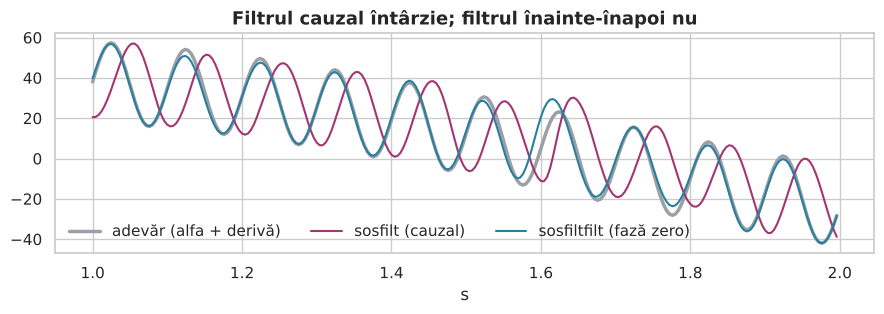

In [10]:
sos = signal.butter(4, 15, btype="low", fs=fs, output="sos")
y_causal = signal.sosfilt(sos, x)
y_zero   = signal.sosfiltfilt(sos, x)

ref = alpha + drift                                    # adevărul de joasă frecvență
def lag(a, b):                                        # întârzierea lui a față de b, în eșantioane
    c = signal.correlate(a - a.mean(), b - b.mean(), mode="full")
    return int(np.argmax(c) - (len(b) - 1))
print("întârziere cauzal    :", lag(y_causal, ref), "eșantioane =", lag(y_causal, ref) / fs * 1000, "ms")
print("întârziere fază zero:", lag(y_zero, ref), "eșantioane")

fig, ax = plt.subplots(figsize=(9, 3.3)); s = slice(250, 500)
ax.plot(t[s], ref[s], color=GREY, lw=2.5, label="adevăr (alfa + derivă)")
ax.plot(t[s], y_causal[s], color=PINK, label="sosfilt (cauzal)"); ax.plot(t[s], y_zero[s], color=BLUE, label="sosfiltfilt (fază zero)")
ax.set(xlabel="s", title="Filtrul cauzal întârzie; filtrul înainte-înapoi nu"); ax.legend(ncol=3); plt.tight_layout(); plt.show()

## 1.7 · Filtre FIR: mai mulți coeficienți, fără feedback, întârziere constantă

Un filtru **FIR** este o medie mobilă ponderată cu `numtaps` coeficienți. Este întotdeauna stabil și are **fază liniară** (întârzierea este constanta `(numtaps−1)/2` eșantioane pentru orice frecvență). Prețul este lungimea. Relația-cheie de proiectare: **lățimea tranziției** (distanța dintre banda de trecere și cea de oprire) este invers proporțională cu `numtaps`. Pentru o fereastră Hamming `numtaps ≈ 3.3·fs / lățimea_tranziției`. Lăsați SciPy să facă calculul cu metoda Kaiser: dați atenuarea și lățimea tranziției, obțineți lungimea și parametrul ferestrei.

coeficienți: 25   întârziere: 12 eșantioane = 48.0 ms


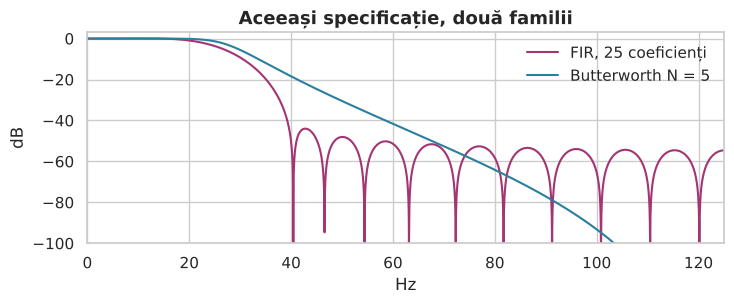

In [11]:
width = 40 - 15                                       # Hz, lățimea tranziției (ca în exemplul Butterworth)
numtaps, beta = signal.kaiserord(ripple=40, width=width / (fs / 2))
numtaps += (numtaps % 2 == 0)                        # lungime impară -> întârziere întreagă
h_fir = signal.firwin(numtaps, 27.5, window=("kaiser", beta), fs=fs)
print("coeficienți:", numtaps, "  întârziere:", (numtaps - 1) // 2, "eșantioane =", (numtaps - 1) / 2 / fs * 1000, "ms")

freq, h = signal.freqz(h_fir, 1, worN=4096, fs=fs)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(freq, 20*np.log10(np.abs(h)+1e-9), color=PINK, label=f"FIR, {numtaps} coeficienți")
fr2, h2 = signal.sosfreqz(signal.butter(buttord_N:=N_min, 27.5, fs=fs, output="sos"), worN=4096, fs=fs)
ax.plot(fr2, 20*np.log10(np.abs(h2)+1e-9), color=BLUE, label=f"Butterworth N = {N_min}")
ax.set(xlim=(0, 125), ylim=(-100, 3), xlabel="Hz", ylabel="dB", title="Aceeași specificație, două familii"); ax.legend(); plt.tight_layout(); plt.show()

**Ce familie alegem?** IIR (Butterworth) atinge aceeași specificație cu o mână de coeficienți, dar are fază neliniară. FIR cere mult mai mulți coeficienți, dar are întârziere constantă și este alegerea potrivită când contează *forma* undei (ECG, evenimente EEG).

## 1.8 · Netezire neliniară: filtrul median și Savitzky–Golay

Filtrele liniare împrăștie un vârf peste vecinii săi. Când problema sunt **vârfurile** (nu zgomotul), folosiți un **filtru median**: parametrul `kernel_size` (impar). Regulă: nucleul trebuie să fie **mai mare decât dublul lățimii vârfului** – un nucleu de 3 elimină doar vârfuri de 1 eșantion.

Când problema este **zgomotul pe un maxim neted**, folosiți **Savitzky–Golay**: ajustează un polinom de grad `polyorder` într-o fereastră de `window_length` eșantioane. Regulă: `window_length` ≈ lățimea celei mai înguste trăsături pe care vreți să o păstrați, `polyorder` 2–4 (mai mare = urmărește datele mai îndeaproape și netezește mai puțin); `polyorder < window_length`.

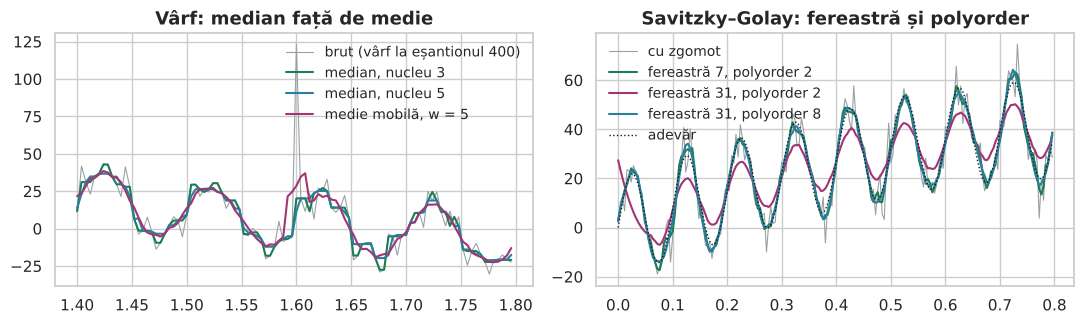

nucleu median 3: RMSE față de adevăr = 0.25
nucleu median 5: RMSE față de adevăr = 0.44
nucleu median 7: RMSE față de adevăr = 0.82


In [12]:
clean = alpha + drift
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
s = slice(350, 450)
ax[0].plot(t[s], x[s], color=GREY, lw=0.8, label="brut (vârf la eșantionul 400)")
for k, c in [(3, GREEN), (5, BLUE)]:
    ax[0].plot(t[s], signal.medfilt(x, k)[s], color=c, label=f"median, nucleu {k}")
ax[0].plot(t[s], np.convolve(x, np.ones(5)/5, "same")[s], color=PINK, label="medie mobilă, w = 5"); ax[0].legend(fontsize=10); ax[0].set_title("Vârf: median față de medie")
sg_noisy = clean + 6 * np.random.default_rng(1).normal(size=t.size)
s = slice(0, 200)
ax[1].plot(t[s], sg_noisy[s], color=GREY, lw=0.8, label="cu zgomot")
for wl, po, c in [(7, 2, GREEN), (31, 2, PINK), (31, 8, BLUE)]:
    ax[1].plot(t[s], signal.savgol_filter(sg_noisy, wl, po)[s], color=c, label=f"fereastră {wl}, polyorder {po}")
ax[1].plot(t[s], clean[s], "k:", lw=1, label="adevăr"); ax[1].legend(fontsize=10); ax[1].set_title("Savitzky–Golay: fereastră și polyorder")
plt.tight_layout(); plt.show()
for k in (3, 5, 7):
    print(f"nucleu median {k}: RMSE față de adevăr = {np.sqrt(np.mean((signal.medfilt(x - noise - mains, k) - clean)**2)):.2f}")

### Tabel de decizie (păstrați-l pe acesta)

| Problemă | Filtru | Parametru | Cum se alege |
|---|---|---|---|
| Zgomot peste banda de interes | Butterworth trece-jos | `fc`, `N` | `fc` între frecvența dorită și cea nedorită; `N` din `buttord` |
| Derivă / variația liniei de bază | Butterworth trece-sus | `fc`, `N` | `fc` ≈ ⅓ din cea mai joasă frecvență dorită; `N` = 2–4 |
| Interferență la o singură frecvență | Notch (`iirnotch`) | `f0`, `Q` | `Q = f0 / lățimea de bandă`; îngust dacă vecinii contează |
| Perioadă cunoscută care trebuie mediată | Medie mobilă | `w` | `w = fs / f_interferență` (sau un multiplu al perioadei) |
| Vârfuri izolate | Median | `kernel_size` | impar, > 2 × lățimea vârfului |
| Zgomot pe maxime netede | Savitzky–Golay | `window_length`, `polyorder` | fereastra ≈ cea mai îngustă trăsătură; polyorder 2–4 |
| Forma undei contează, offline | FIR + `filtfilt` sau fază liniară | `numtaps` | `numtaps ≈ 3.3·fs / lățimea tranziției` |
| Timp real | doar cauzal (`sosfilt`) | — | acceptați întârzierea |

## 1.9 · Date reale 1 — traficul rutier orar: izolarea ciclului zilnic

`Metro_Interstate_Traffic_Volume.csv`: vehicule pe oră pe o autostradă din SUA (2012–2018). Frecvența de eșantionare este `fs = 1 eșantion/oră`, deci **frecvența Nyquist este 0.5 cicluri/oră**. Luăm anul 2017 pe o grilă orară regulată; lipsesc 47 de ore, pe care le completăm prin interpolare liniară în timp (Partea 3 explică de ce și când este acceptabil).

Întrebarea de proiectare: *„Vreau doar componenta zilnică.”* Zilnic = 1/24 cicluri/oră = 0.0417. Ciclul săptămânal este 1/168 = 0.0060, armonica de jumătate de zi 1/12 = 0.083. Deci trece-banda trebuie să lase să treacă 0.0417 și să respingă 0.006 și 0.083: `[1/30, 1/20]`.

ore lipsă: 47


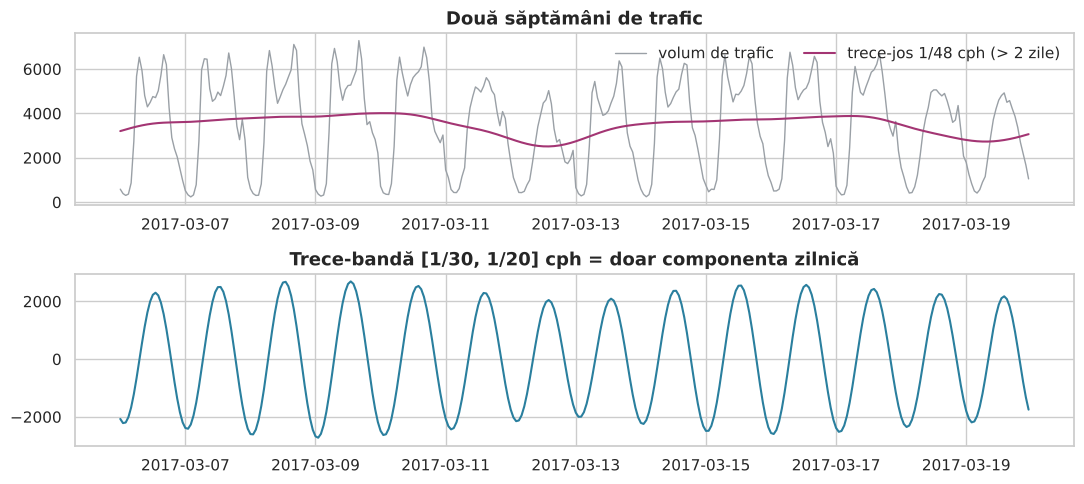

std brut 1982  | componenta zilnică 1647 | partea lentă 458


In [13]:
tr = pd.read_csv("Metro_Interstate_Traffic_Volume.csv", parse_dates=["date_time"]).drop_duplicates("date_time").set_index("date_time")
vol = tr.loc["2017", "traffic_volume"].reindex(pd.date_range("2017-01-01", "2017-12-31 23:00", freq="h"))
print("ore lipsă:", int(vol.isna().sum()))
vol = vol.interpolate(method="time")

fs_h = 1.0                                           # eșantioane pe oră
sos_day = signal.butter(2, [1/30, 1/20], btype="bandpass", fs=fs_h, output="sos")
sos_low = signal.butter(4, 1/48, btype="low", fs=fs_h, output="sos")
daily = pd.Series(signal.sosfiltfilt(sos_day, vol.values), index=vol.index)
slow  = pd.Series(signal.sosfiltfilt(sos_low, vol.values), index=vol.index)

fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=False)
w = slice("2017-03-06", "2017-03-19")
ax[0].plot(vol[w], color=GREY, lw=1, label="volum de trafic"); ax[0].plot(slow[w], color=PINK, label="trece-jos 1/48 cph (> 2 zile)"); ax[0].legend(ncol=2); ax[0].set_title("Două săptămâni de trafic")
ax[1].plot(daily[w], color=BLUE); ax[1].set_title("Trece-bandă [1/30, 1/20] cph = doar componenta zilnică")
plt.tight_layout(); plt.show()
print(f"std brut {vol.std():.0f}  | componenta zilnică {daily.std():.0f} | partea lentă {slow.std():.0f}")

Cele două filtre împart varianța: componenta zilnică este o sinusoidă curată a cărei amplitudine se schimbă cu ziua săptămânii (weekendurile sunt mai mici), iar partea lentă conține scăderile din weekenduri și efectele sărbătorilor. *Dubla creastă* a orelor de vârf a fost eliminată odată cu tot ce nu se află la 24 h – o amintire că un trece-bandă vă dă o **sinusoidă**, nu forma originală.

## 1.10 · Date reale 2 — puterea pe benzi EEG și CO₂ din biroul inteligent: vârfuri față de zgomot

Fișierul EEG **nu** conține EEG brut: casca (NeuroSky) raportează deja, o dată pe secundă, puterea în opt benzi. Fiecare coloană este o serie temporală lentă cu `fs = 1 Hz`; cozile grele cer un `log10`. CO₂ din biroul inteligent este eșantionat la fiecare minut și are șase valori eronate injectate (două mici, patru mari). Două probleme diferite → două filtre diferite.

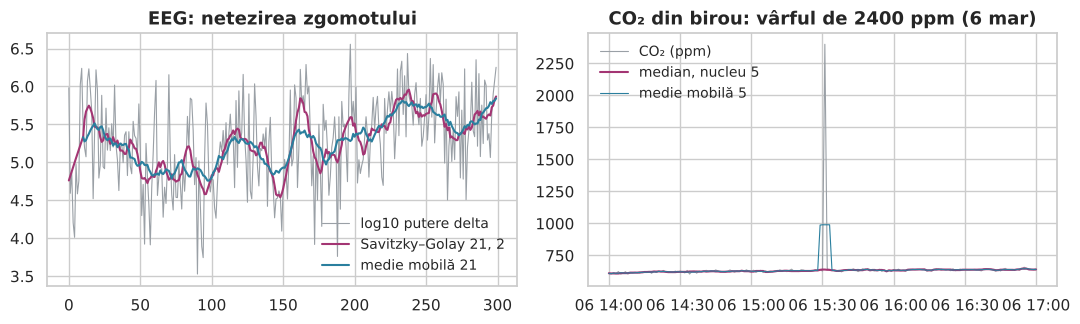

maximum CO2  brut: 2400.0  median-5: 732.0  medie-5: 1000.0


In [14]:
eeg = pd.read_csv("sleepy_driver_eeg_data.csv")
ld = np.log10(eeg["delta"])                                         # 1 eșantion pe secundă
off = pd.read_csv("smart_office_dataset.csv", parse_dates=["timestamp"], index_col="timestamp")
co2 = off["co2_ppm"].interpolate()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
s = slice(0, 300)
ax[0].plot(ld[s], color=GREY, lw=0.8, label="log10 putere delta")
ax[0].plot(signal.savgol_filter(ld, 21, 2)[s], color=PINK, label="Savitzky–Golay 21, 2")
ax[0].plot(ld.rolling(21, center=True).mean()[s], color=BLUE, label="medie mobilă 21"); ax[0].legend(fontsize=10); ax[0].set_title("EEG: netezirea zgomotului")
d = slice("2026-03-06 14:00", "2026-03-06 17:00")
ax[1].plot(co2[d], color=GREY, lw=0.8, label="CO₂ (ppm)")
ax[1].plot(pd.Series(signal.medfilt(co2.values, 5), index=co2.index)[d], color=PINK, label="median, nucleu 5")
ax[1].plot(co2.rolling(5, center=True).mean()[d], color=BLUE, lw=0.8, label="medie mobilă 5"); ax[1].legend(fontsize=10, loc="upper left"); ax[1].set_title("CO₂ din birou: vârful de 2400 ppm (6 mar)")
plt.tight_layout(); plt.show()
print("maximum CO2  brut:", co2.max(), " median-5:", signal.medfilt(co2.values, 5).max().round(0), " medie-5:", co2.rolling(5, center=True).mean().max().round(0))

**Ce reținem din Partea 1.** (1) Stabiliți banda în Hz, (2) alegeți tipul și frecvențele de tăiere, (3) alegeți cel mai mic ordin/cea mai mică lungime care îndeplinește specificația, (4) verificați *răspunsul în frecvență*, nu doar curba filtrată, (5) decideți între cauzal și fază zero, (6) pentru vârfuri izolate instrumentul potrivit nu este deloc un filtru trece-jos.

# Partea 2 — Cum proiectăm un pas de eliminare a tendinței

O **tendință** este o schimbare lentă a nivelului. Multe metode (spectre, corelație, detecția punctelor de schimbare, ARIMA, PCA pe ferestre) presupun că nivelul este constant, de aceea eliminăm mai întâi tendința. Întrebările de proiectare sunt:

1. **Ce fel de tendință?** O dreaptă, o curbă, o rătăcire de tip mers aleator, o linie de bază zilnică/săptămânală?
2. **Ce trebuie să supraviețuiască?** Sezonalitatea (ciclul zilnic) trebuie să rămână *sau* să dispară, în funcție de scop.
3. **Câtă libertate dau modelului de tendință?** Gradul polinomului, lungimea ferestrei, frecvența de tăiere, decalajul diferențierii – fiecare metodă are *un* număr care controlează libertatea. Prea puțină libertate lasă tendință în date (**subpotrivire**); prea multă libertate elimină semnalul însuși (**supraspotrivire**).

Folosim o singură serie sintetică orară, de 14 zile, cu o tendință **cunoscută**: o tendință pătratică, un ciclu de 24 de ore și zgomot.

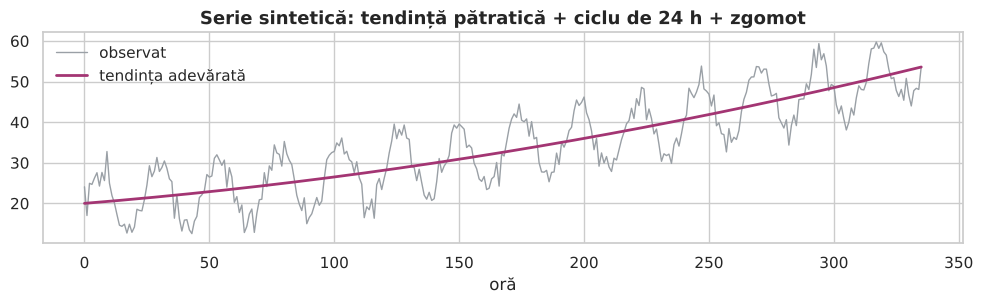

In [15]:
n = 14 * 24
h = np.arange(n)
rng = np.random.default_rng(3)
true_trend = 20 + 0.05 * h + 0.00015 * h**2          # pătratică: o cunoaștem
season     = 8 * np.sin(2 * np.pi * h / 24)
y = true_trend + season + 2 * rng.normal(size=n)

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(h, y, color=GREY, lw=1, label="observat"); ax.plot(h, true_trend, color=PINK, lw=2, label="tendința adevărată"); ax.legend(); ax.set(xlabel="oră", title="Serie sintetică: tendință pătratică + ciclu de 24 h + zgomot")
plt.tight_layout(); plt.show()

## 2.1 · Eliminarea tendinței cu un polinom: gradul este parametrul

`signal.detrend(y, type="constant")` scade media, `type="linear"` o dreaptă ajustată. Pentru orice alt grad folosiți `np.polynomial.Polynomial.fit(h, y, deg)` (rescalează intern `x`, ceea ce evită problemele numerice ale lui `np.polyfit` cu `x` mari).

**Cum alegem gradul:** rezervați *ultima* parte a seriei, ajustați pe prima parte și priviți eroarea pe partea rezervată. Un grad bun are acolo o eroare mică; un grad prea mare se potrivește frumos pe partea de antrenare și **explodează** în afara ei (extrapolare).

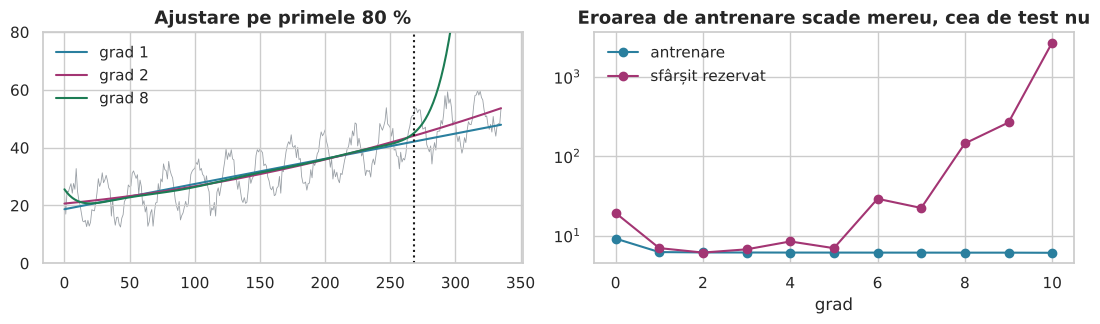

grad               0     1     2     3     4     5      6      7       8       9        10
rmse_antrenare   9.16  6.20  6.13  6.12  6.11  6.11   6.10   6.10    6.09    6.09     6.07
rmse_test       19.27  6.95  6.11  6.71  8.43  6.94  29.08  22.28  144.73  265.92  2701.51


In [16]:
split = int(0.8 * n)
rows = []
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for deg, c in [(1, BLUE), (2, PINK), (8, GREEN)]:
    p = np.polynomial.Polynomial.fit(h[:split], y[:split], deg)
    ax[0].plot(h, p(h), color=c, label=f"grad {deg}")
ax[0].plot(h, y, color=GREY, lw=0.6, zorder=0); ax[0].axvline(split, color="k", ls=":"); ax[0].set_ylim(0, 80); ax[0].legend(); ax[0].set_title("Ajustare pe primele 80 %")
for deg in range(0, 11):
    p = np.polynomial.Polynomial.fit(h[:split], y[:split], deg)
    rows.append((deg, np.sqrt(np.mean((y[:split]-p(h[:split]))**2)), np.sqrt(np.mean((y[split:]-p(h[split:]))**2))))
r = pd.DataFrame(rows, columns=["grad", "rmse_antrenare", "rmse_test"]).set_index("grad")
ax[1].semilogy(r.index, r.rmse_antrenare, "o-", color=BLUE, label="antrenare"); ax[1].semilogy(r.index, r.rmse_test, "o-", color=PINK, label="sfârșit rezervat")
ax[1].set(xlabel="grad", title="Eroarea de antrenare scade mereu, cea de test nu"); ax[1].legend()
plt.tight_layout(); plt.show()
print(r.round(2).T.to_string())

Eroarea de **antrenare** scade monoton cu gradul (întotdeauna!), eroarea pe datele **rezervate** are un minim la gradul adevărat. *Nu alegeți niciodată gradul după eroarea de antrenare.* Un avertisment înrudit: un polinom de grad mare nu se potrivește doar tendinței, ci poate absorbi și părți lente ale sezonalității.

## 2.2 · Media / mediana glisantă: fereastra este parametrul

O medie glisantă centrată cu fereastra `w` estimează nivelul local. **Regulă: `w` trebuie să fie multiplu al perioadei sezoniere.** Atunci fiecare fereastră conține cicluri complete, iar ciclul se mediază la zero; orice altă valoare lasă în „tendință” o ondulație a componentei sezoniere. O fereastră prea scurtă urmărește zgomotul; o fereastră mai lungă mediază mai mult zgomot, dar nu poate urmări curbura (părtinire în curbe) și pierde `w/2` eșantioane la ambele capete. În grafic, eroarea scade la 24, 48, 72… și este mare între aceste valori.

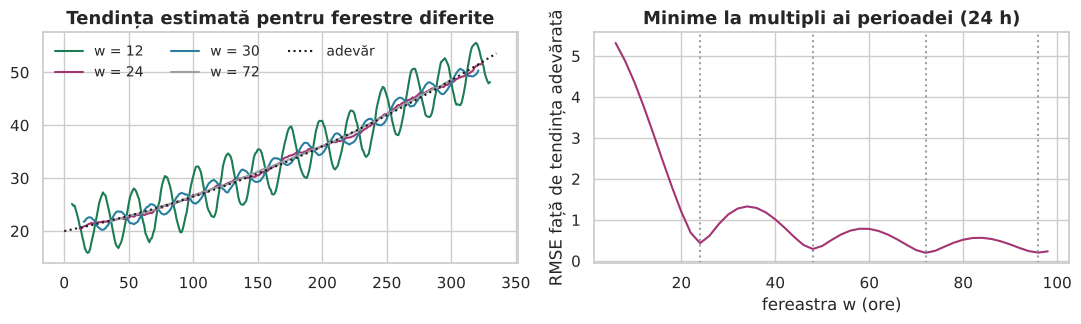

               0      1      2     3
fereastră  12.00  24.00  30.00  72.0
RMSE        3.76   0.43   1.14   0.2


In [17]:
ys = pd.Series(y)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
res = []
for w, c in [(12, GREEN), (24, PINK), (30, BLUE), (72, GREY)]:
    tr_est = ys.rolling(w, center=True).mean()
    ax[0].plot(tr_est, color=c, label=f"w = {w}")
    ok = tr_est.notna()
    res.append((w, np.sqrt(np.mean((tr_est[ok] - true_trend[ok])**2))))
ax[0].plot(true_trend, "k:", label="adevăr"); ax[0].legend(ncol=3, fontsize=10); ax[0].set_title("Tendința estimată pentru ferestre diferite")
ws = np.arange(6, 100, 2)
err = []
for w in ws:
    te = ys.rolling(w, center=True).mean(); ok = te.notna(); err.append(np.sqrt(np.mean((te[ok]-true_trend[ok])**2)))
ax[1].plot(ws, err, color=PINK); [ax[1].axvline(k, color=GREY, ls=":") for k in (24, 48, 72, 96)]
ax[1].set(xlabel="fereastra w (ore)", ylabel="RMSE față de tendința adevărată", title="Minime la multipli ai perioadei (24 h)")
plt.tight_layout(); plt.show()
print(pd.DataFrame(res, columns=["fereastră", "RMSE"]).round(2).T.to_string())

## 2.3 · Diferențierea: decalajul și ordinul sunt parametrii

`y.diff(lag)` calculează `y[t] − y[t−lag]`. Diferențierea obișnuită (`lag=1`) elimină un **nivel constant**; aplicată de două ori elimină o **tendință liniară**; `lag = perioada` (diferențiere sezonieră) elimină un **ciclu care se repetă** și, *în plus*, o tendință lentă. Prețul este triplu: pierdeți `lag` eșantioane; **varianța zgomotului crește** (pentru zgomot alb o diferență înmulțește varianța cu 2, două diferențe cu 6); iar rezultatul este *schimbarea* seriei, nu nivelul ei (o puteți anula cu `cumsum`).

zgomot alb, raportul varianțelor după 1 diferență : 1.96
zgomot alb, raportul varianțelor după 2 diferențe: 5.8


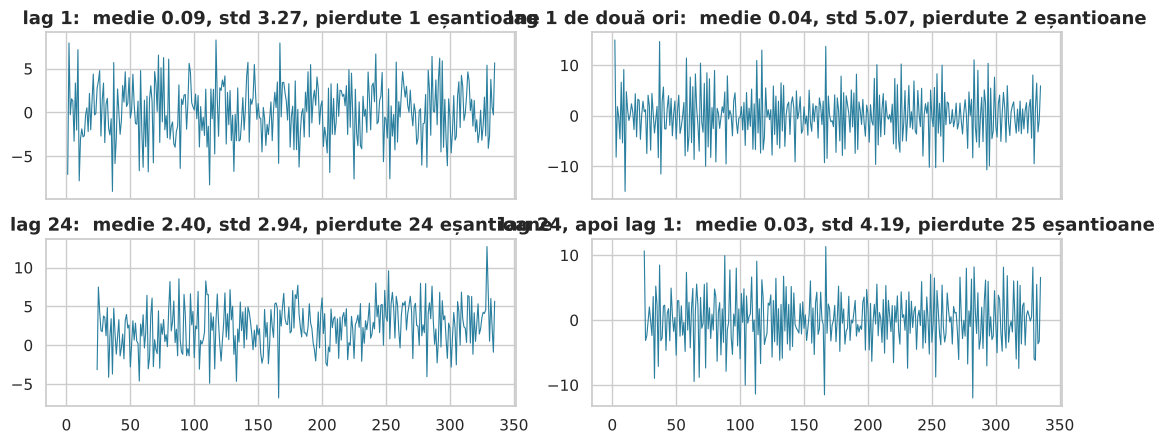

In [18]:
noise_only = pd.Series(np.random.default_rng(5).normal(size=5000))
print("zgomot alb, raportul varianțelor după 1 diferență :", round(noise_only.diff().var() / noise_only.var(), 2))
print("zgomot alb, raportul varianțelor după 2 diferențe:", round(noise_only.diff().diff().var() / noise_only.var(), 2))

d1  = ys.diff(1); d2 = ys.diff(1).diff(1); d24 = ys.diff(24); d24_1 = ys.diff(24).diff(1)
fig, ax = plt.subplots(2, 2, figsize=(11, 4.6), sharex=True)
for a, s, ttl in zip(ax.ravel(), [d1, d2, d24, d24_1], ["lag 1", "lag 1 de două ori", "lag 24", "lag 24, apoi lag 1"]):
    a.plot(s, color=BLUE, lw=0.8); a.set_title(f"{ttl}:  medie {s.mean():.2f}, std {s.std():.2f}, pierdute {int(s.isna().sum())} eșantioane")
plt.tight_layout(); plt.show()

Cu o tendință pătratică și un ciclu de 24 de ore, o diferență cu lag 24 elimină ciclul, iar *pătraticul* devine o tendință **liniară**; o diferență suplimentară cu lag 1 face media constantă. Aceasta este diferențierea „sezonieră + obișnuită” folosită în ARIMA.

## 2.4 · Filtrul trece-sus și eliminarea tendinței prin Fourier: frecvența de tăiere este parametrul

Tendința este „tot ce este mai lent decât cel mai lent fenomen care ne interesează”. Un **trece-sus** Butterworth cu frecvența de tăiere `fc` o elimină. Regula: puneți `fc` **mult sub cea mai joasă frecvență dorită** (aici ciclul de 24 h: 1/24 = 0.0417 cicluri/oră) și deasupra tendinței. Verificați câștigul la frecvența dorită: trebuie să fie aproape de 0 dB.

Eliminarea tendinței prin Fourier (metoda din vechiul laborator) pune pe zero toți coeficienții FFT sub o frecvență-prag. Este un trece-sus de tip *perete drept*: simplu, dar presupune că semnalul este periodic în fereastră, deci creează artefacte la margini.

fc = 1/200 cph : câștig la ciclul zilnic =  -0.00 dB   (sosfiltfilt îl dublează:  -0.00 dB)
fc = 1/72 cph : câștig la ciclul zilnic =  -0.01 dB   (sosfiltfilt îl dublează:  -0.01 dB)
fc = 1/30 cph : câștig la ciclul zilnic =  -1.00 dB   (sosfiltfilt îl dublează:  -2.00 dB)


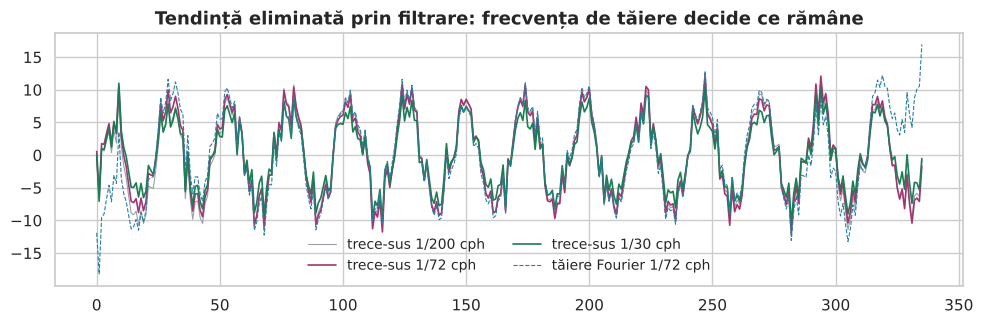

In [19]:
def fourier_detrend(v, fs, f_cut):
    F = np.fft.rfft(v); fr = np.fft.rfftfreq(len(v), 1 / fs)
    F[fr < f_cut] = 0
    return np.fft.irfft(F, n=len(v))

hp = {}
for fc in (1/200, 1/72, 1/30):
    sos = signal.butter(3, fc, btype="high", fs=1.0, output="sos")
    hp[fc] = signal.sosfiltfilt(sos, y)
    print(f"fc = 1/{1/fc:.0f} cph : câștig la ciclul zilnic = {gain_db(sos, 1/24, 1.0):6.2f} dB   (sosfiltfilt îl dublează: {2*gain_db(sos, 1/24, 1.0):6.2f} dB)")
fd = fourier_detrend(y, 1.0, 1/72)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(hp[1/200], color=GREY, lw=0.8, label="trece-sus 1/200 cph"); ax.plot(hp[1/72], color=PINK, lw=1.2, label="trece-sus 1/72 cph"); ax.plot(hp[1/30], color=GREEN, lw=1.2, label="trece-sus 1/30 cph")
ax.plot(fd, color=BLUE, lw=0.8, ls="--", label="tăiere Fourier 1/72 cph"); ax.legend(ncol=2, fontsize=10); ax.set(title="Tendință eliminată prin filtrare: frecvența de tăiere decide ce rămâne")
plt.tight_layout(); plt.show()

## 2.5 · Staționar în jurul tendinței sau staționar la diferențiere? (de ce există *ambele*, și eliminarea tendinței, și diferențierea)

Două procese foarte diferite arată asemănător: o **tendință deterministă + zgomot** (eliminați dreapta → staționar) și un **mers aleator cu derivă** („tendința” este zgomotul acumulat; eliminarea unei drepte lasă o curbă rătăcitoare; doar diferențierea îl face staționar). Testul **Augmented Dickey–Fuller** (`statsmodels.tsa.stattools.adfuller`) are ipoteza nulă *„există o rădăcină unitate (nestaționar)”*: o **valoare p mică (<0.05) înseamnă staționar**.

In [20]:
from statsmodels.tsa.stattools import adfuller
rng = np.random.default_rng(7); m = 600; tt = np.arange(m)
trend_stat = 0.05 * tt + rng.normal(size=m)                    # tendință deterministă + zgomot
walk       = np.cumsum(0.05 + rng.normal(size=m))              # mers aleator cu derivă
def adf_p(v): return adfuller(v, autolag="AIC")[1]
resid_line = lambda v: v - np.polynomial.Polynomial.fit(tt, v, 1)(tt)
tab = pd.DataFrame({"brut": [adf_p(trend_stat), adf_p(walk)],
                    "după eliminarea unei drepte": [adf_p(resid_line(trend_stat)), adf_p(resid_line(walk))],
                    "după 1 diferență": [adf_p(np.diff(trend_stat)), adf_p(np.diff(walk))]},
                   index=["tendință + zgomot", "mers aleator + derivă"]).round(4)
print(tab.to_string())

                         brut  după eliminarea unei drepte  după 1 diferență
tendință + zgomot      0.9631                        0.000               0.0
mers aleator + derivă  0.3060                        0.106               0.0


Citiți tabelul: pentru *tendință + zgomot*, eliminarea dreptei funcționează (p ≈ 0) – diferențierea funcționează și ea, dar supra-diferențiază (produce o eroare de tip medie mobilă neinversabilă). Pentru *mersul aleator*, eliminarea unei drepte lasă încă p mare (nestaționar); **doar diferența** trece testul. Folosiți testul, nu imaginea, ca să decideți.

## 2.6 · STL: tendință, componentă sezonieră și rest dintr-o singură mișcare

`statsmodels.tsa.seasonal.STL` ajustează atât tendința, cât și componenta sezonieră cu LOESS. Parametri: `period` (perioada cunoscută), `seasonal` (fereastră impară, în *perioade*: cât de repede poate varia forma sezonieră; ≥ 7; mai mare = mai rigid), `trend` (fereastră impară, în eșantioane; implicit ≈ 1.5·period/(1−1.5/seasonal); mai mic urmărește schimbări mai rapide) și `robust=True` (reduce ponderea valorilor aberante).

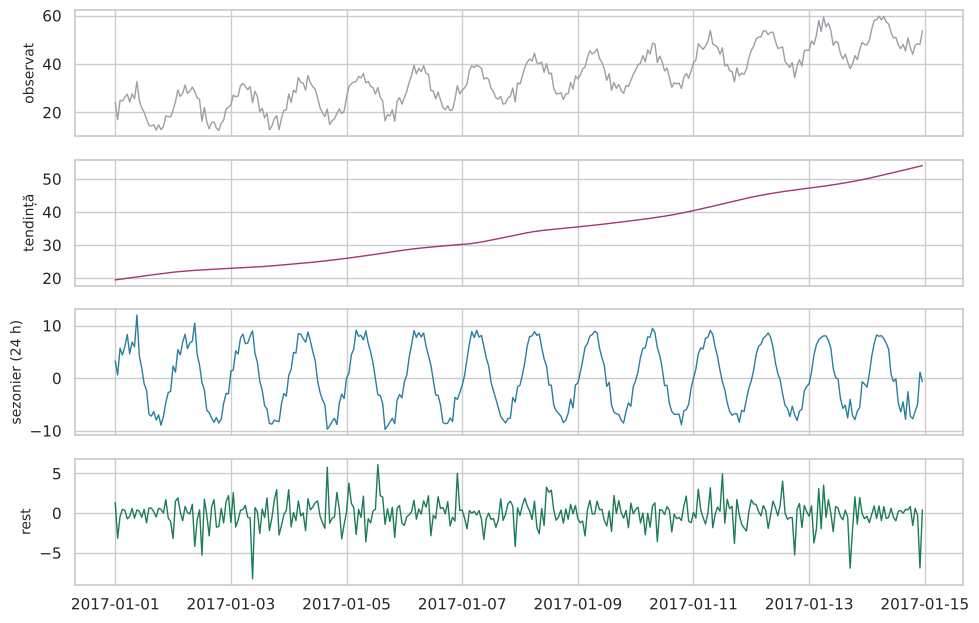

forța tendinței 0.97   forța sezonalității 0.92   (1 = explicat complet)
RMSE al tendinței STL față de cea adevărată: 0.39


In [21]:
from statsmodels.tsa.seasonal import STL
res = STL(pd.Series(y, index=pd.date_range("2017-01-01", periods=n, freq="h")), period=24, seasonal=7, robust=True).fit()
fig, ax = plt.subplots(4, 1, figsize=(10, 6.4), sharex=True)
for a, s, ttl, c in zip(ax, [res.observed, res.trend, res.seasonal, res.resid], ["observat", "tendință", "sezonier (24 h)", "rest"], [GREY, PINK, BLUE, GREEN]):
    a.plot(s, color=c, lw=1); a.set_ylabel(ttl, fontsize=10)
plt.tight_layout(); plt.show()
Ft = max(0, 1 - res.resid.var() / (res.trend + res.resid).var()); Fs = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
print(f"forța tendinței {Ft:.2f}   forța sezonalității {Fs:.2f}   (1 = explicat complet)")
print("RMSE al tendinței STL față de cea adevărată:", round(float(np.sqrt(np.mean((res.trend.values - true_trend)**2))), 2))

## 2.7 · Date reale — trafic (sezonalitate săptămânală) și EEG (derivă lentă)

Traficul 2017: ciclul dominant este ziua, dar tiparul *săptămânal* (zi lucrătoare față de weekend) este la fel de important. **Diferențierea sezonieră la lag 24** elimină ciclul zilnic, dar lasă efectul de weekend; **lag 168** le elimină pe amândouă. Alegeți lagul cu **deviația standard rămasă mai mică**.

EEG: în timpul condusului puterea de bază derivă lent (oboseală, contactul electrodului). Eșantionarea este de 1 Hz; vrem să păstrăm schimbările mai rapide de ~5 minute, deci o **mediană** glisantă de 301 s (fereastră impară, robustă la rafale) este linia de bază, iar un trece-sus la 1/300 Hz face același lucru în domeniul frecvență.

diferență sezonieră lag  24: std =  1011.2   (std brut 1981.5)
diferență sezonieră lag 168: std =   574.4   (std brut 1981.5)


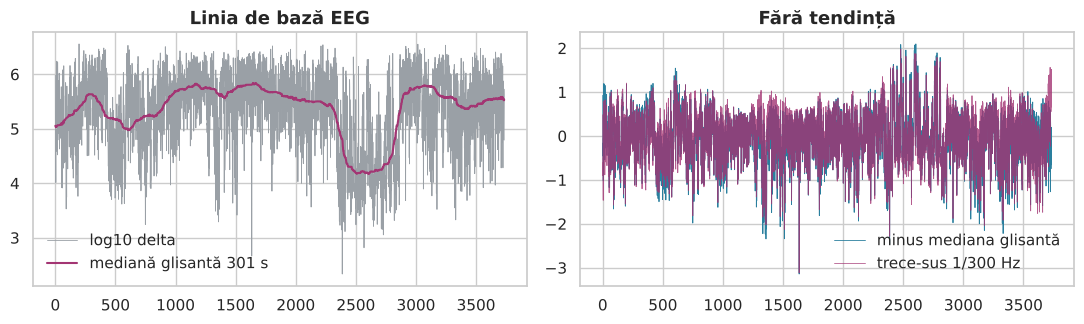

In [22]:
tr = pd.read_csv("Metro_Interstate_Traffic_Volume.csv", parse_dates=["date_time"]).drop_duplicates("date_time").set_index("date_time")
vol = tr.loc["2017", "traffic_volume"].reindex(pd.date_range("2017-01-01", "2017-12-31 23:00", freq="h")).interpolate(method="time")
for lag in (24, 168):
    d = vol.diff(lag).dropna(); print(f"diferență sezonieră lag {lag:3d}: std = {d.std():7.1f}   (std brut {vol.std():.1f})")

eeg = pd.read_csv("sleepy_driver_eeg_data.csv")
ld = np.log10(eeg["delta"])
base_med = ld.rolling(301, center=True, min_periods=1).median()
sos_hp = signal.butter(2, 1/300, btype="high", fs=1.0, output="sos")
hp_eeg = signal.sosfiltfilt(sos_hp, ld.values)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(ld, color=GREY, lw=0.6, label="log10 delta"); ax[0].plot(base_med, color=PINK, label="mediană glisantă 301 s"); ax[0].legend(); ax[0].set_title("Linia de bază EEG")
ax[1].plot(ld - base_med, color=BLUE, lw=0.6, label="minus mediana glisantă"); ax[1].plot(hp_eeg, color=PINK, lw=0.6, alpha=0.8, label="trece-sus 1/300 Hz"); ax[1].legend(); ax[1].set_title("Fără tendință")
plt.tight_layout(); plt.show()

**Ce reținem din Partea 2.** Gradul / fereastra / lagul / frecvența de tăiere este un buton de tip *părtinire–varianță*: alegeți-l după un criteriu de validare (eroare pe date rezervate, ondulația la perioadă, testul ADF, câștigul la frecvența dorită), niciodată după „arată plat”. Țineți minte perioada sezonieră de fiecare dată când alegeți o fereastră.

# Partea 3 — Cum proiectăm interpolarea valorilor lipsă

Valorile lipsă sunt de trei feluri și fiecare cere alt tratament:

* **eșantioane izolate** (un pachet pierdut): aproape orice metodă funcționează;
* **goluri** (un senzor oprit minute sau ore): metoda contează, iar lungimea golului decide dacă are sens să completăm deloc;
* **valori lipsă la început / la sfârșit** (înainte de prima sau după ultima măsurătoare): aceasta este *extrapolare*, de obicei nepermisă.

Întrebări de proiectare: (1) *Cât de lungi sunt golurile în comparație cu scala de timp a semnalului?* (2) *Semnalul este o mărime netedă (temperatură), o stare (ușă deschisă/închisă) sau un număr?* (3) *Sunt momentele de timp regulate?* (4) *De unde știu că metoda este bună?* – **mascând valori cunoscute și măsurând eroarea**.

## 3.1 · Mai întâi privim golurile

Fișierul de trafic pare complet, dar nu este: după reindexarea pe o grilă orară regulată apar găurile.

In [23]:
tr = pd.read_csv("Metro_Interstate_Traffic_Volume.csv", parse_dates=["date_time"])
print("rânduri:", len(tr), "  momente de timp duplicate:", int(tr.date_time.duplicated().sum()))
tr = tr.drop_duplicates("date_time").set_index("date_time")
vol = tr.loc["2017", "traffic_volume"].reindex(pd.date_range("2017-01-01", "2017-12-31 23:00", freq="h"))

isna = vol.isna()
run_id = (isna != isna.shift()).cumsum()
gaps = isna.groupby(run_id).agg(["first", "size"]).query("first")["size"]       # lungimea fiecărui gol
print("ore lipsă:", int(isna.sum()), "  număr de goluri:", len(gaps), "  cel mai lung gol:", int(gaps.max()), "h")
print(gaps.value_counts().sort_index().to_string())

rânduri: 48204   momente de timp duplicate: 7629
ore lipsă: 47   număr de goluri: 21   cel mai lung gol: 9 h
size
1    15
3     2
4     1
6     1
7     1
9     1


## 3.2 · Metodele și parametrii lor

| Metodă | Apel | Parametru | Comportament |
|---|---|---|---|
| ultima observație reportată | `s.ffill(limit=)` | `limit` (nr. maxim de pași) | corectă pentru *stări*; greșită pentru semnale netede |
| cel mai apropiat | `s.interpolate("nearest")` | – | trepte |
| liniar | `s.interpolate("linear")` sau `"time"` | `limit`, `limit_area` | alegere implicită robustă; taie colțurile |
| spline cubic | `interpolate.CubicSpline(x, y, bc_type=)` | condiția la limită | neted, dar **depășește** datele |
| PCHIP | `interpolate.PchipInterpolator` | – | neted, **nu depășește niciodată** (monoton între puncte) |
| Akima | `interpolate.Akima1DInterpolator` | – | neted, oscilații mici |
| copie sezonieră | `s.fillna(s.shift(period))` | `period` | folosește *aceeași oră de ieri / din săptămâna trecută* |

`limit` este un **parametru de siguranță**: „nu completa mai mult de `limit` eșantioane consecutive”. `limit_area="inside"` completează doar golurile dintre două valori valide (fără extrapolare). Vechea clasă `interp1d` este *legacy* în SciPy; folosiți clasele de mai sus sau `np.interp`.

**Testăm pe date sintetice cu adevăr cunoscut.** Semnalul are perioada de 60 de eșantioane (o componentă lentă) și una mai rapidă de 17 eșantioane. Tăiem goluri de lungime 2, 8, 45 la mijloc și comparăm eroarea.

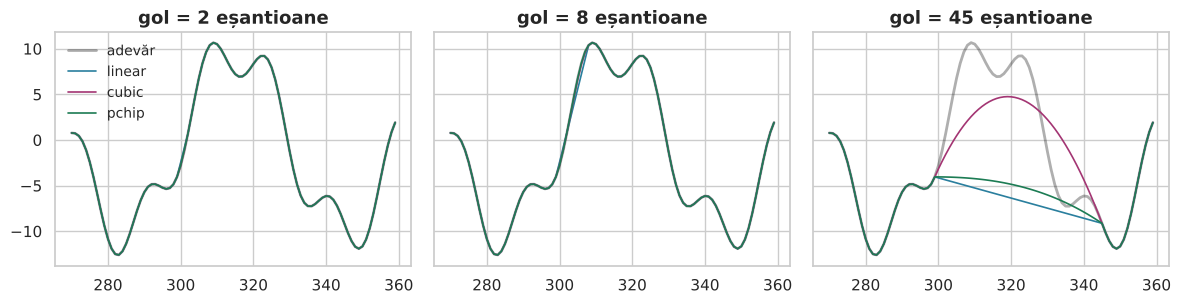

gap        2     8      45
method                    
akima    0.04  0.30   5.90
cubic    0.01  0.09   4.64
ffill    2.19  8.78   9.32
linear   0.34  0.78  10.72
nearest  1.60  3.98  10.42
pchip    0.07  0.04   9.73


In [24]:
rng = np.random.default_rng(1)
N = 600; k = np.arange(N)
truth = 10 * np.sin(2 * np.pi * k / 60) + 3 * np.sin(2 * np.pi * k / 17 + 1)

def fill(series, how):
    x = np.arange(len(series)); ok = series.notna().values
    if how == "ffill":   return series.ffill()
    if how == "nearest": return series.interpolate("nearest")
    if how == "linear":  return series.interpolate("linear")
    if how == "cubic":   return pd.Series(interpolate.CubicSpline(x[ok], series.values[ok])(x), index=series.index)
    if how == "pchip":   return pd.Series(interpolate.PchipInterpolator(x[ok], series.values[ok])(x), index=series.index)
    if how == "akima":   return pd.Series(interpolate.Akima1DInterpolator(x[ok], series.values[ok])(x), index=series.index)

methods = ["ffill", "nearest", "linear", "cubic", "pchip", "akima"]
rows = []
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, L in zip(ax, [2, 8, 45]):
    s = pd.Series(truth.copy()); gap = slice(300, 300 + L); s.iloc[gap] = np.nan
    a.plot(k[270:360], truth[270:360], color="k", lw=2, alpha=0.35, label="adevăr")
    for m, c in zip(["linear", "cubic", "pchip"], [BLUE, PINK, GREEN]):
        f_ = fill(s, m); a.plot(k[270:360], f_.values[270:360], color=c, lw=1.2, label=m)
    a.set_title(f"gol = {L} eșantioane")
    for m in methods:
        f_ = fill(s, m); rows.append((L, m, np.sqrt(np.mean((f_.values[gap] - truth[gap])**2))))
ax[0].legend(fontsize=10); plt.tight_layout(); plt.show()
print(pd.DataFrame(rows, columns=["gap", "method", "rmse"]).pivot(index="method", columns="gap", values="rmse").round(2).to_string())

**Citirea tabelului.** Gol scurt: orice metodă netedă este bună, `ffill`/`nearest` sunt mai slabe. Gol mediu: metodele de tip spline câștigă *dacă* golul este mult mai scurt decât perioada celei mai rapide componente. Gol lung (45 de eșantioane = trei sferturi din perioada lentă): **orice** metodă eșuează – informația pur și simplu nu este în date. Regulă practică: interpolarea este de încredere când golul este mai scurt de aproximativ **un sfert din perioada celei mai rapide componente care vă interesează**. Pentru goluri mai lungi folosiți un model (copie sezonieră, regresie pe alți senzori) și marcați valorile ca *imputate*.

**Depășirea (overshoot).** Un spline cubic este neted, dar poate depăși datele lângă un salt – periculos pentru mărimi care nu pot fi negative (numărători de trafic, umiditate, ocupare).

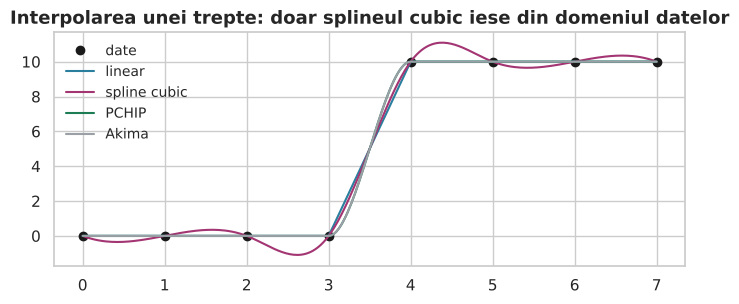

maximul splineului cubic: 11.09   minimul: -1.09


In [25]:
xs = np.array([0, 1, 2, 3, 4, 5, 6, 7.0]); ys_ = np.array([0, 0, 0, 0, 10, 10, 10, 10.0])     # o treaptă
xf = np.linspace(0, 7, 300)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(xs, ys_, "ko", label="date")
for m, c, f_ in [("linear", BLUE, np.interp(xf, xs, ys_)), ("spline cubic", PINK, interpolate.CubicSpline(xs, ys_)(xf)),
                 ("PCHIP", GREEN, interpolate.PchipInterpolator(xs, ys_)(xf)), ("Akima", GREY, interpolate.Akima1DInterpolator(xs, ys_)(xf))]:
    ax.plot(xf, f_, color=c, label=m)
ax.legend(fontsize=10); ax.set_title("Interpolarea unei trepte: doar splineul cubic iese din domeniul datelor")
plt.tight_layout(); plt.show()
print("maximul splineului cubic:", round(interpolate.CubicSpline(xs, ys_)(xf).max(), 2), "  minimul:", round(interpolate.CubicSpline(xs, ys_)(xf).min(), 2))

## 3.3 · Momente de timp neregulate: poziții, nu indici

Dacă eșantioanele nu sunt echidistante, interpolarea după *indice* este greșită; trebuie să folosească *timpul*. `pandas` o face cu `method="time"` (indexul trebuie să fie `DatetimeIndex`), NumPy cu `np.interp(x_new, x_known, y_known)`.

In [26]:
idx = pd.to_datetime(["2026-01-01 00:00", "2026-01-01 00:10", "2026-01-01 01:00", "2026-01-01 01:10", "2026-01-01 01:20"])
s = pd.Series([10.0, np.nan, 20.0, np.nan, 40.0], index=idx)
print(pd.DataFrame({"brut": s, "liniar (după poziție)": s.interpolate("linear"), "time (după moment de timp)": s.interpolate("time")}).to_string())

                     brut  liniar (după poziție)  time (după moment de timp)
2026-01-01 00:00:00  10.0                   10.0                   10.000000
2026-01-01 00:10:00   NaN                   15.0                   11.666667
2026-01-01 01:00:00  20.0                   20.0                   20.000000
2026-01-01 01:10:00   NaN                   30.0                   30.000000
2026-01-01 01:20:00  40.0                   40.0                   40.000000


Valoarea de la 00:10 este 10 + (20−10)·(10/60) = 11.67 după timp, dar 15 după poziție: rezultatul după poziție ignoră că între 00:10 și 01:00 trec 50 de minute.

## 3.4 · Evaluarea onestă: mascăm valori cunoscute, completăm, măsurăm

Pe date reale nu există adevăr, așa că îl **creăm**: ascundem 10 % din valorile *cunoscute*, alese la întâmplare (izolate), și un bloc continuu de 6 ore, le completăm cu mai multe metode și calculăm eroarea doar pe valorile ascunse. Parametrii experimentului (fracția, lungimea blocului) trebuie să imite golurile reale.

In [27]:
vol_f = vol.interpolate(method="time")                       # o versiune completă folosită ca pseudo-adevăr
known = vol.notna()
rng = np.random.default_rng(0)
iso = rng.choice(np.flatnonzero(known.values), size=int(0.10 * known.sum()), replace=False)

def test_methods(mask_pos):
    s = vol.copy(); s.iloc[mask_pos] = np.nan
    out = {}
    out["linear"] = s.interpolate("linear")
    out["pchip"] = pd.Series(interpolate.PchipInterpolator(np.flatnonzero(s.notna()), s.dropna().values)(np.arange(len(s))), index=s.index)
    out["aceeași oră ieri"] = s.fillna(s.shift(24)).interpolate("linear")
    out["aceeași oră săptămâna trecută"] = s.fillna(s.shift(168)).interpolate("linear")
    out["ffill"] = s.ffill()
    ok = known.values.copy(); sel = np.zeros(len(s), bool); sel[mask_pos] = True; sel &= ok
    return {m: float(np.sqrt(np.mean((v.values[sel] - vol.values[sel])**2))) for m, v in out.items()}

block_start = int(np.flatnonzero(vol.index == "2017-06-14 08:00")[0])
res_iso = test_methods(iso)
res_blk = test_methods(np.arange(block_start, block_start + 6))
print(pd.DataFrame({"10 % izolate": res_iso, "bloc de 6 ore (14 iun, 08–13 h)": res_blk}).round(0).to_string())

                               10 % izolate  bloc de 6 ore (14 iun, 08–13 h)
linear                                443.0                            458.0
pchip                                 361.0                            391.0
aceeași oră ieri                     1031.0                            148.0
aceeași oră săptămâna trecută         594.0                            211.0
ffill                                 907.0                            638.0


Pentru ore izolate lipsă orice metodă netedă funcționează (seria este netedă de la o oră la alta). Pentru un **bloc de 6 ore în ora de vârf a dimineții**, interpolarea liniară taie vârful; copierea *aceleiași ore din săptămâna precedentă* păstrează forma. Aceasta este lecția de proiectare: *metoda potrivită depinde de lungimea golului în raport cu structura sezonieră.*

## 3.5 · Imputare multivariată (KNN) — și greșeala clasică

`KNNImputer(n_neighbors=k)` completează o valoare lipsă cu media celor mai apropiate `k` rânduri, **unde „cel mai apropiat” se măsoară pe celelalte coloane**. Două reguli: (1) dați-i *mai multe coloane informative* (altfel „apropiat” nu înseamnă nimic: cu o singură coloană imputer-ul returnează media coloanei – o linie plată!); (2) **scalați** coloanele, pentru că distanța amestecă unitățile de măsură.

In [28]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
off = pd.read_csv("smart_office_dataset.csv", parse_dates=["timestamp"], index_col="timestamp")
print("lipsă:", off.isna().sum().to_dict())
gap_idx = off.index[off.temp_c.isna()]
print("întrerupere de la", gap_idx[0], "până la", gap_idx[-1], f"({len(gap_idx)} min)")

# gol artificial de 31 de minute marți 3 martie, 10:20-10:50, unde cunoaștem valorile
art = off.copy(); sl = slice("2026-03-03 10:20", "2026-03-03 10:50"); truth_blk = off.loc[sl, "temp_c"].copy(); art.loc[sl, "temp_c"] = np.nan

one_col = KNNImputer(n_neighbors=5).fit_transform(art[["temp_c"]])[:, 0]
feat = art[["temp_c", "occupancy", "temp_out_c"]].copy(); feat["hour"] = art.index.hour + art.index.minute / 60
Z = StandardScaler().fit_transform(feat); Zi = KNNImputer(n_neighbors=5).fit_transform(Z)
multi = StandardScaler().fit(feat.fillna(feat.mean())).inverse_transform(Zi)[:, 0]
cmp_ = pd.DataFrame({"truth": truth_blk,
                     "liniar": art["temp_c"].interpolate("linear")[sl],
                     "KNN, 1 coloană": pd.Series(one_col, index=art.index)[sl],
                     "KNN, 4 coloane scalate": pd.Series(multi, index=art.index)[sl],
                     "aceeași oră ieri": off["temp_c"].shift(1440)[sl]})
print((cmp_.drop(columns="truth").sub(cmp_.truth, axis=0) ** 2).mean().pow(0.5).round(3).to_string())

lipsă: {'temp_c': 31, 'humidity_pct': 31, 'co2_ppm': 31, 'occupancy': 0, 'temp_out_c': 0}
întrerupere de la 2026-03-05 10:20:00 până la 2026-03-05 10:50:00 (31 min)


liniar                    0.107
KNN, 1 coloană            2.677
KNN, 4 coloane scalate    0.132
aceeași oră ieri          0.198


KNN pe o singură coloană este *cel mai slab* (o constantă egală cu media coloanei), motiv pentru care apelul `KNNImputer` pe o singură coloană din vechiul laborator era înșelător. Cu variabile informative devine competitiv, dar pentru un gol scurt într-un senzor cu variație lentă, **interpolarea liniară este adesea la fel de bună și mult mai simplă**. Folosiți KNN când lipsesc mai mulți senzori corelați, *în același interval de timp*, în moduri diferite.

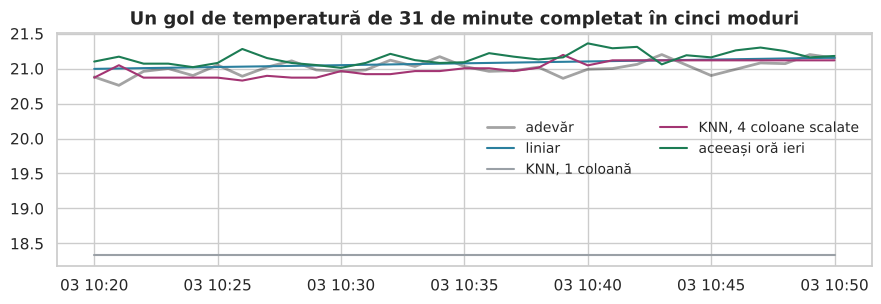

In [29]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(cmp_.index, cmp_["truth"], "k", lw=2, alpha=0.4, label="adevăr")
for c_, col in zip(["liniar", "KNN, 1 coloană", "KNN, 4 coloane scalate", "aceeași oră ieri"], [BLUE, GREY, PINK, GREEN]):
    ax.plot(cmp_.index, cmp_[c_], color=col, label=c_)
ax.legend(fontsize=10, ncol=2); ax.set_title("Un gol de temperatură de 31 de minute completat în cinci moduri"); plt.tight_layout(); plt.show()

**Ce reținem din Partea 3.** (1) Priviți lungimea golurilor (`reindex`, lungimi de secvențe). (2) Goluri scurte: liniar sau PCHIP; goluri lungi: folosiți un model al sezonalității sau alt senzor și *marcați-le*. (3) `limit` și `limit_area` vă protejează de extrapolarea tăcută. (4) Validați întotdeauna prin mascarea valorilor cunoscute: raportați un RMSE pe metodă și pe lungimea golului.

# Partea 4 — Cum proiectăm un detector de valori aberante

O **valoare aberantă** (outlier) este o valoare care nu aparține procesului care le-a produs pe celelalte. Două cauze cer două tratamente: o **defecțiune** (vârf de senzor, −5 °C în interior, 9831 mm de ploaie într-o oră) trebuie eliminată sau reparată; un **extrem real** (un ambuteiaj, o rafală puternică în EEG) poate fi chiar lucrul pe care vrem să-l găsim. Un detector poate spune doar „neobișnuit”: *decizia* vă aparține și pornește de la cunoștințele din domeniu (limite fizice, domeniul senzorului) *înainte* de orice statistică.

Fiecare detector are un parametru de **prag**. Întrebarea de proiectare este mereu: *câte alarme false și câte omisiuni pot accepta?* Măsurăm asta cu precizie, recall și F1 pe date sintetice în care am plantat valorile aberante.

## 4.1 · Reguli globale: scorul z, MAD, IQR

* **scorul z** `|x − media| / std > k`: `k` = 3 este alegerea clasică (0.27 % dintr-o distribuție normală se află în afară). Slăbiciune: media și abaterea standard sunt **ele însele** umflate de valorile aberante (*mascare*).
* **Scorul z modificat (mediană / MAD)**: `0.6745·|x − mediana| / MAD > 3.5`, unde `MAD = mediana(|x − mediana|)`. Mediana și MAD abia se mișcă în prezența valorilor aberante.
* **Regula IQR** (Tukey): marcați valorile din afara `[Q1 − c·IQR, Q3 + c·IQR]`; `c` = 1.5 marchează valori aberante „moderate”, `c` = 3 pe cele „îndepărtate”. Presupune o distribuție aproximativ simetrică.

In [30]:
def make_values(seed, n=1000, frac=0.01, shift=8):
    rng = np.random.default_rng(seed)
    v = rng.normal(50, 5, n); truth = np.zeros(n, bool)
    idx = rng.choice(n, int(frac * n), replace=False); v[idx] += rng.choice([-1, 1], len(idx)) * rng.uniform(shift, shift + 4, len(idx)) * 5; truth[idx] = True
    return v, truth

def flag_z(v, k):   return np.abs(v - v.mean()) / v.std() > k
def flag_mad(v, k=3.5): med = np.median(v); mad = np.median(np.abs(v - med)); return 0.6745 * np.abs(v - med) / mad > k
def flag_iqr(v, c): q1, q3 = np.percentile(v, [25, 75]); return (v < q1 - c * (q3 - q1)) | (v > q3 + c * (q3 - q1))

rows = []
for frac in (0.01, 0.15):
    v, truth = make_values(0, frac=frac)
    for name, fl in [("z, k=2", flag_z(v, 2)), ("z, k=3", flag_z(v, 3)), ("z, k=4", flag_z(v, 4)), ("MAD, 3.5", flag_mad(v)), ("IQR, 1.5", flag_iqr(v, 1.5)), ("IQR, 3", flag_iqr(v, 3))]:
        p, r, f1 = prf(fl, truth); rows.append((f"{frac:.0%} aberante", name, int(fl.sum()), round(p, 2), round(r, 2), round(f1, 2)))
print(pd.DataFrame(rows, columns=["date", "regula", "marcate", "precizie", "recall", "F1"]).to_string(index=False))

        date   regula  marcate  precizie  recall   F1
 1% aberante   z, k=2       18      0.56    1.00 0.71
 1% aberante   z, k=3       10      1.00    1.00 1.00
 1% aberante   z, k=4       10      1.00    1.00 1.00
 1% aberante MAD, 3.5       12      0.83    1.00 0.91
 1% aberante IQR, 1.5       18      0.56    1.00 0.71
 1% aberante   IQR, 3       10      1.00    1.00 1.00
15% aberante   z, k=2      126      1.00    0.84 0.91
15% aberante   z, k=3       16      1.00    0.11 0.19
15% aberante   z, k=4        0      0.00    0.00 0.00
15% aberante MAD, 3.5      150      1.00    1.00 1.00
15% aberante IQR, 1.5      152      0.99    1.00 0.99
15% aberante   IQR, 3      150      1.00    1.00 1.00


**Citirea tabelului.** Cu 1 % valori aberante toate regulile funcționează; `k = 2` produce multe alarme false (circa 5 % dintr-o distribuție normală se află în afara ±2σ: precizia se prăbușește), `k = 4` este sigur. Cu **15 %** valori aberante, abaterea standard este atât de umflată încât scorul z *ratează* cele mai multe (recall-ul scade) – mascare – în timp ce MAD și IQR rămân fiabile. **Regulă:** dacă nu cunoașteți contaminarea, folosiți regulile robuste.

**Date asimetrice.** Regulile IQR și z presupun simetrie. Numărătorile, duratele, precipitațiile și puterile pe benzi EEG sunt *asimetrice la dreapta*: coada dreaptă este marcată deși este normală. Transformați mai întâi (`log`), detectați, interpretați.

date log-normale: IQR(1.5) marchează 99 valori; pe log(date): 14 valori


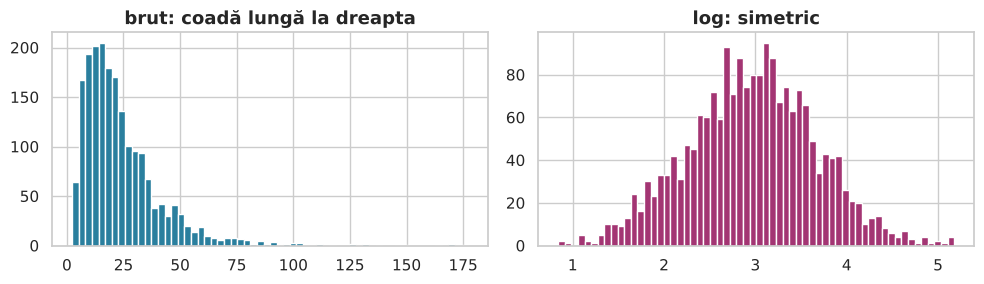

In [31]:
rng = np.random.default_rng(2)
skew = rng.lognormal(mean=3, sigma=0.7, size=2000)
print("date log-normale: IQR(1.5) marchează", int(flag_iqr(skew, 1.5).sum()), "valori; pe log(date):", int(flag_iqr(np.log(skew), 1.5).sum()), "valori")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(skew, bins=60, color=BLUE); ax[0].set_title("brut: coadă lungă la dreapta"); ax[1].hist(np.log(skew), bins=60, color=PINK); ax[1].set_title("log: simetric")
plt.tight_layout(); plt.show()

## 4.2 · Valori aberante într-o serie temporală: filtrul Hampel

Un prag global eșuează când **nivelul se schimbă** (ciclu zilnic, tendință): o valoare normală de după-amiază poate fi „neobișnuită” pentru întreaga serie. **Filtrul Hampel** aplică regula MAD într-o **fereastră glisantă**: `window` (semi-lățimea este `window//2`) și `n_sigmas`. Un eșantion este valoare aberantă dacă `|x − mediana glisantă| > n_sigmas · 1.4826 · MAD glisant`. Alegeți fereastra **suficient de lungă încât să conțină mai multe eșantioane normale de fiecare parte a unui vârf** (cel puțin 2 × cel mai lung vârf + 1) și **suficient de scurtă încât nivelul să fie aproape constant în interiorul ei**. Un prag minim al scalei (floor) evită alarmele false în porțiunile plate, unde MAD este zero.

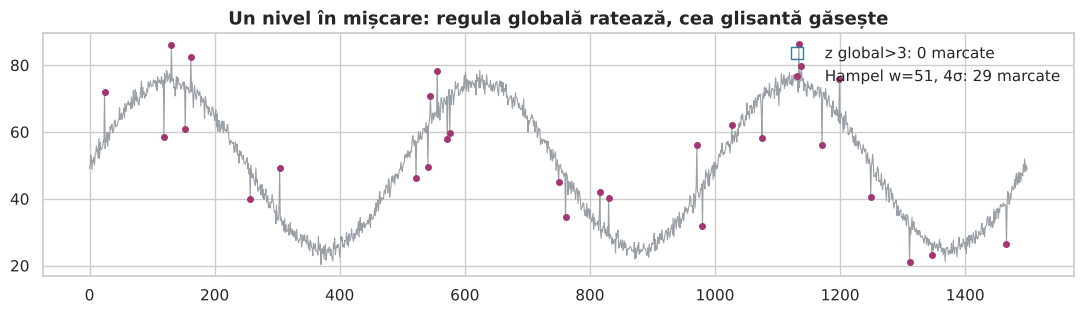

n_sigmas      2     3     4
fereastră                  
5          0.20  0.29  0.31
11         0.28  0.49  0.67
21         0.28  0.60  0.86
51         0.35  0.79  0.93
201        0.38  0.79  0.75
z global>3 : [0.0, 0.0, 0.0]


In [32]:
def hampel(s, window=11, n_sigmas=3, floor=0.0):
    s = pd.Series(s)
    med = s.rolling(window, center=True, min_periods=1).median()
    mad = 1.4826 * (s - med).abs().rolling(window, center=True, min_periods=1).median()
    return ((s - med).abs() > n_sigmas * np.maximum(mad, floor)).values

rng = np.random.default_rng(4); n = 1500; tt = np.arange(n)
level = 50 + 25 * np.sin(2 * np.pi * tt / 500)               # nivel cu variație lentă
ts = level + rng.normal(0, 1.5, n); truth = np.zeros(n, bool)
pos = rng.choice(np.arange(10, n - 10), 25, replace=False); ts[pos] += rng.choice([-1, 1], 25) * rng.uniform(8, 15, 25); truth[pos] = True

fig, ax = plt.subplots(figsize=(11, 3.3))
ax.plot(ts, color=GREY, lw=0.8)
g = flag_z(ts, 3); h_ = hampel(ts, 51, 4)
ax.plot(np.flatnonzero(g), ts[g], "s", mfc="none", color=BLUE, ms=9, label=f"z global>3: {g.sum()} marcate")
ax.plot(np.flatnonzero(h_), ts[h_], "o", color=PINK, ms=4, label=f"Hampel w=51, 4σ: {h_.sum()} marcate"); ax.legend(); ax.set_title("Un nivel în mișcare: regula globală ratează, cea glisantă găsește")
plt.tight_layout(); plt.show()
rows = []
for w in (5, 11, 21, 51, 201):
    for ns in (2, 3, 4):
        p, r, f1 = prf(hampel(ts, w, ns), truth); rows.append((w, ns, round(p, 2), round(r, 2), round(f1, 2)))
r = pd.DataFrame(rows, columns=["fereastră", "n_sigmas", "P", "R", "F1"]); print(r.pivot(index="fereastră", columns="n_sigmas", values="F1").to_string())
print("z global>3 :", [round(v, 2) for v in prf(g, truth)])

Grila F1 arată cele două moduri de eșec: o **fereastră prea mică** (5) urmărește vârful însuși, o **fereastră prea mare** (201) nu mai vede nivelul local; `n_sigmas = 2` dă alarme false, `4` este sigur dacă vârfurile sunt mari.

## 4.3 · Detectoare multivariate: Isolation Forest, LOF, DBSCAN

Un rând poate fi normal în fiecare coloană și neobișnuit în *combinație* (CO₂ mare cu ocupare zero). Trei parametri de înțeles:

* **Isolation Forest** – `contamination`: *fracția de rânduri de marcat*. Aceasta **nu este estimată** de model: dacă spuneți 0.05, marchează 5 % indiferent de date. `"auto"` folosește în schimb un prag pe scor. Folosiți `score_samples` ca să vedeți separarea reală.
* **Local Outlier Factor** – `n_neighbors`: mai mic = detectează anomalii locale, dar este zgomotos.
* **DBSCAN** – `eps` (raza) și `min_samples`: punctele care nu se află în nicio regiune densă sunt etichetate **zgomot (−1)**. Cere trăsături **scalate**. Alegeți `eps` la *cotul* graficului distanțelor sortate la al `k`-lea vecin.

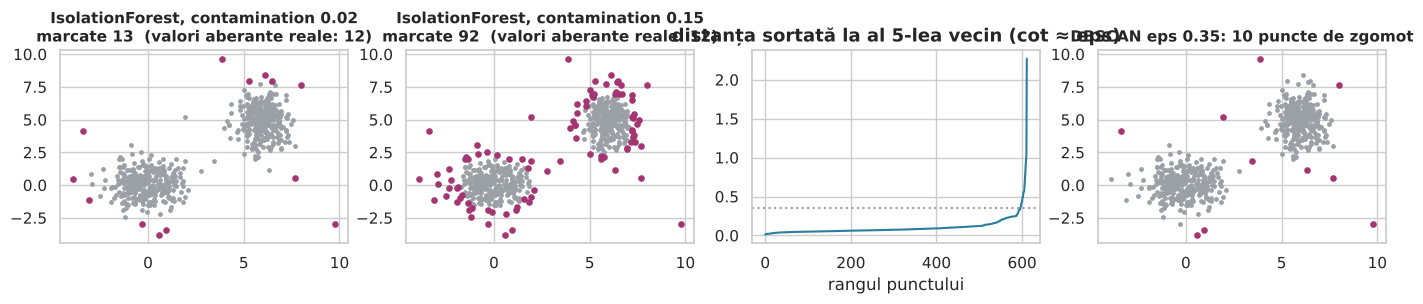

eps  0.1: zgomot 119  clustere 6  precizie 0.09  recall 0.92
eps  0.2: zgomot  37  clustere 2  precizie 0.22  recall 0.67
eps 0.35: zgomot  10  clustere 2  precizie 0.70  recall 0.58
eps  0.6: zgomot   4  clustere 1  precizie 1.00  recall 0.33
eps  1.0: zgomot   1  clustere 1  precizie 1.00  recall 0.08


In [33]:
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(0)
A = rng.normal([0, 0], [1, 1], (300, 2)); B = rng.normal([6, 5], [0.7, 1.2], (300, 2)); O = rng.uniform(-4, 10, (12, 2))
X2 = np.vstack([A, B, O]); is_out = np.r_[np.zeros(600, bool), np.ones(12, bool)]

fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for a, cont in zip(ax[:2], [0.02, 0.15]):
    iso = IsolationForest(contamination=cont, n_estimators=200, random_state=0).fit(X2); fl = iso.predict(X2) == -1
    a.scatter(*X2[~fl].T, s=6, color=GREY); a.scatter(*X2[fl].T, s=14, color=PINK); a.set_title(f"IsolationForest, contamination {cont}\nmarcate {fl.sum()}  (valori aberante reale: 12)", fontsize=11)
Xs = StandardScaler().fit_transform(X2)
kd = np.sort(NearestNeighbors(n_neighbors=5).fit(Xs).kneighbors(Xs)[0][:, -1])
ax[2].plot(kd, color=BLUE); ax[2].set(title="distanța sortată la al 5-lea vecin (cot ≈ eps)", xlabel="rangul punctului"); ax[2].axhline(0.35, color=GREY, ls=":")
lab = DBSCAN(eps=0.35, min_samples=5).fit_predict(Xs)
ax[3].scatter(*X2[lab >= 0].T, s=6, color=GREY); ax[3].scatter(*X2[lab == -1].T, s=14, color=PINK); ax[3].set_title(f"DBSCAN eps 0.35: {int((lab == -1).sum())} puncte de zgomot", fontsize=11)
plt.tight_layout(); plt.show()
for eps in (0.1, 0.2, 0.35, 0.6, 1.0):
    l = DBSCAN(eps=eps, min_samples=5).fit_predict(Xs); p, r, f1 = prf(l == -1, is_out)
    print(f"eps {eps:4}: zgomot {int((l == -1).sum()):3d}  clustere {len(set(l) - {-1})}  precizie {p:.2f}  recall {r:.2f}")

`contamination = 0.15` marchează 15 % din rânduri deși doar 2 % sunt valori aberante – un *parametru al utilizatorului*, nu o proprietate a datelor. DBSCAN: un `eps` prea mic face totul zgomot, un `eps` prea mare îmbină valorile aberante în clustere; cotul curbei k-distanțelor este locul potrivit.

## 4.4 · Ce facem după detecție

| Acțiune | Când |
|---|---|
| setăm la `NaN` și interpolăm (Partea 3) | defecțiuni de senzor în semnale netede |
| limităm (`clip(lower, upper)`, winsorizare) | valori reale, dar extreme, care ar domina un model |
| păstrăm și **marcăm** (o nouă coloană booleană) | veți modela anomaliile sau nu sunteți siguri |
| ștergem rândul | doar pentru observații independente, niciodată într-o serie temporală regulată |

## 4.5 · Date reale — biroul inteligent și traficul

*Mai întâi regulile din domeniu.* Temperatura interioară de −5 °C, CO₂ de 90 sau 150 ppm (sub nivelul exterior de ≈ 420 ppm), peste 2 000 ppm într-o cameră cu câteva persoane – fiecare este fizic implauzibilă. Statistica vine pe locul doi: Hampel cu fereastră de 15 minute (vârfurile durează 1–2 eșantioane) și 5σ. **Pragul minim al scalei** (cea mai mică scală acceptată, aici zgomotul senzorului de câțiva ppm) contează: în porțiunile liniștite MAD este aproape zero, iar fără prag minim sunt marcate mici ondulații.

regula fizică        : 6 valori -> [150.0, 150.0, 2100.0, 2250.0, 2250.0, 2400.0]
Hampel 15, 5σ, prag minim 3: 20 valori (14 alarme false în porțiunile liniștite: MAD este acolo ~1-2 ppm)
Hampel 15, 5σ, prag minim 8: 6 valori -> [150.0, 150.0, 2100.0, 2250.0, 2250.0, 2400.0]
z global>3           : 6 valori
temperatură <0 : 6 eșantioane la 2026-03-07 06:40:00

trafic: temp == 0 K -> 10 rânduri;  rain_1h max = 9831.3 mm (următorul ca mărime este 55.63 mm)
traffic_volume == 0 -> 2 rânduri


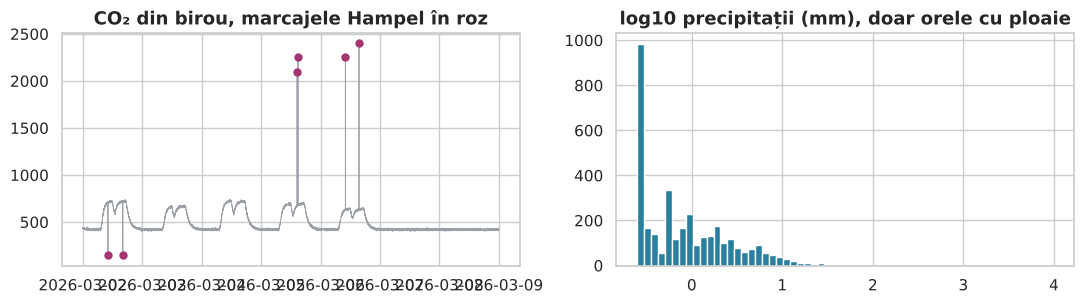

In [34]:
off = pd.read_csv("smart_office_dataset.csv", parse_dates=["timestamp"], index_col="timestamp")
rule = (off.co2_ppm < 300) | (off.co2_ppm > 1500)
c = off.co2_ppm.interpolate()
hp3 = pd.Series(hampel(c, window=15, n_sigmas=5, floor=3.0), index=off.index)      # prag minim al scalei prea mic
hp  = pd.Series(hampel(c, window=15, n_sigmas=5, floor=8.0), index=off.index)      # prag minim ≈ zgomotul senzorului (câțiva ppm pe minut)
g = pd.Series(flag_z(off.co2_ppm.dropna().values, 3), index=off.co2_ppm.dropna().index)
print("regula fizică        :", int(rule.sum()), "valori ->", list(off.co2_ppm[rule].round(0)))
print("Hampel 15, 5σ, prag minim 3:", int(hp3.sum()), "valori (14 alarme false în porțiunile liniștite: MAD este acolo ~1-2 ppm)")
print("Hampel 15, 5σ, prag minim 8:", int(hp.sum()), "valori ->", list(c[hp].round(0)))
print("z global>3           :", int(g.sum()), "valori")
print("temperatură <0 :", int((off.temp_c < 0).sum()), "eșantioane la", off.index[off.temp_c < 0][0])

tr = pd.read_csv("Metro_Interstate_Traffic_Volume.csv", parse_dates=["date_time"])
print("\ntrafic: temp == 0 K ->", int((tr.temp == 0).sum()), "rânduri;  rain_1h max =", tr.rain_1h.max(), "mm (următorul ca mărime este", tr.rain_1h.nlargest(2).iloc[1], "mm)")
print("traffic_volume == 0 ->", int((tr.traffic_volume == 0).sum()), "rânduri")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(off.co2_ppm, color=GREY, lw=0.6); ax[0].plot(off.co2_ppm[hp], "o", color=PINK, ms=5); ax[0].set_title("CO₂ din birou, marcajele Hampel în roz")
ax[1].hist(np.log10(tr.rain_1h[tr.rain_1h > 0]), bins=60, color=BLUE); ax[1].set_title("log10 precipitații (mm), doar orele cu ploaie"); plt.tight_layout(); plt.show()

**Ce reținem din Partea 4.** Începeți cu fizica, apoi o regulă **robustă** (MAD/Hampel), reglați pragul pe valori aberante plantate și tratați *fracția marcată* ca pe un număr de inspectat (un 15 % neașteptat este o greșeală în parametru, nu în date).

# Partea 5 — Cum proiectăm reducerea dimensionalității

Prea multe trăsături dăunează: modelele se supra-ajustează, distanțele își pierd sensul, graficele devin imposibile. Două familii de remedii:

* **extragerea de trăsături** – construim trăsături *noi* din combinații ale celor vechi (PCA, autoencoder, t-SNE);
* **selecția de trăsături** – *păstrăm un subset* dintre cele vechi (varianță, corelație, teste univariate, penalizare L1).

Întrebările de proiectare: *Câte dimensiuni păstrez?* *În ce scală sunt măsurate trăsăturile?* *Este structura liniară?* *Va fi rezultatul folosit de un model (atunci reducerea trebuie ajustată în interiorul validării încrucișate, doar pe partea de antrenare)?*

## 5.1 · Un set de date sintetic cu structură cunoscută

Trei factori ascunși generează 10 trăsături observate (fiecare un amestec al factorilor plus zgomot), măsurate în **unități foarte diferite**. Ținta `y` depinde de primul factor. Cunoaștem răspunsul corect: **3 componente**.

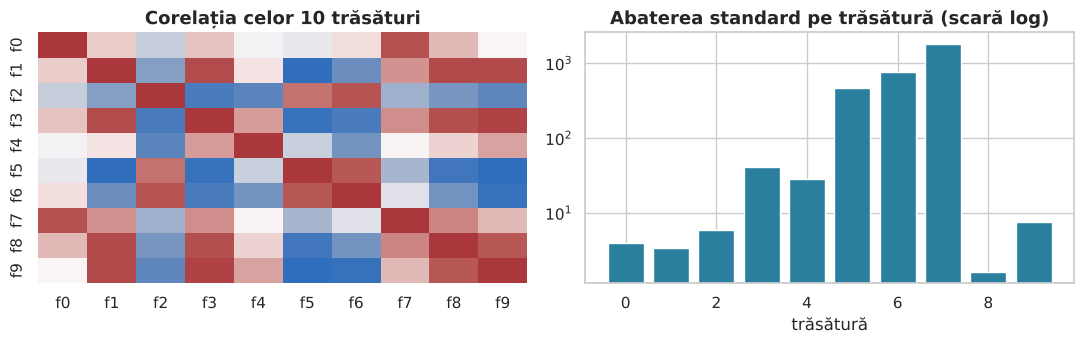

In [35]:
def make_latent(seed=0, n=600):
    rng = np.random.default_rng(seed)
    F = rng.normal(size=(n, 3)) * np.array([3.0, 2.0, 1.5])                   # 3 factori ascunși
    M = rng.normal(size=(3, 10))                                                # amestec
    X = F @ M + 0.6 * rng.normal(size=(n, 10))
    scale = np.array([1, 1, 1, 10, 10, 100, 100, 1000, 1, 1.0])                 # unități diferite
    y = (F[:, 0] + 0.3 * rng.normal(size=n) > 0).astype(int)
    return pd.DataFrame(X * scale, columns=[f"f{i}" for i in range(10)]), y, F

Xd, yd, Fd = make_latent()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.heatmap(Xd.corr(), cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax[0], cbar=False); ax[0].set_title("Corelația celor 10 trăsături")
ax[1].bar(range(10), Xd.std(), color=BLUE); ax[1].set_yscale("log"); ax[1].set(title="Abaterea standard pe trăsătură (scară log)", xlabel="trăsătură")
plt.tight_layout(); plt.show()

## 5.2 · PCA: mai întâi scalarea, apoi numărul de componente

PCA găsește direcțiile cu **varianța cea mai mare**. Varianța depinde de **unități**: o trăsătură măsurată în mii domină prima componentă doar din cauza unității. **Standardizați mai întâi** (`StandardScaler`), cu excepția cazului în care toate trăsăturile au aceeași unitate.

Câte componente `k`? Patru reguli standard, care ar trebui să fie de acord:

1. **varianța cumulată** ≥ 90 % (`PCA(n_components=0.90)` o face automat);
2. **graficul scree**: *cotul* unde valorile proprii se aplatizează;
3. **Kaiser**: păstrați componentele cu valoare proprie > 1 (pe date standardizate: mai multă varianță decât o trăsătură originală);
4. **analiza paralelă**: păstrați componentele a căror valoare proprie o depășește pe cea a zgomotului pur de aceeași formă.

ponderea PC1  date brute: 0.82   standardizat: 0.66
trăsătura cu cel mai mare |loading| pe PC1 (brut): 7   (trăsătura cu cea mai mare unitate)
componente cu varianță cumulată >= 90 %: 3
Kaiser (valoare proprie > 1): 3    analiză paralelă: 3


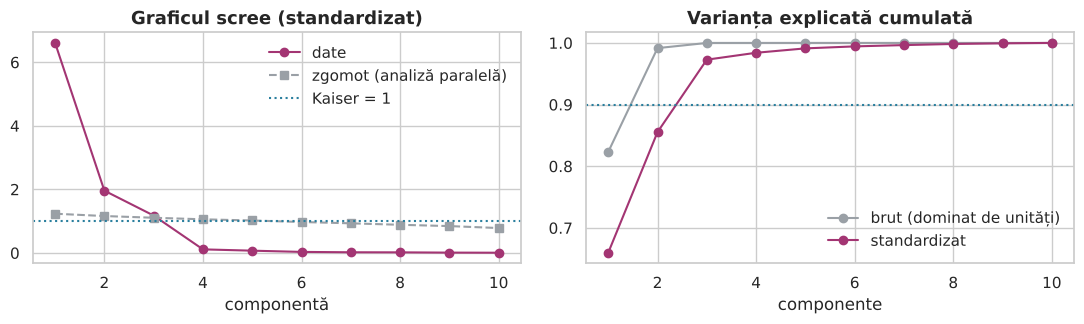

In [36]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca_raw = PCA().fit(Xd); pca_std = PCA().fit(StandardScaler().fit_transform(Xd))
print("ponderea PC1  date brute:", round(pca_raw.explained_variance_ratio_[0], 2), "  standardizat:", round(pca_std.explained_variance_ratio_[0], 2))
print("trăsătura cu cel mai mare |loading| pe PC1 (brut):", int(np.abs(pca_raw.components_[0]).argmax()), "  (trăsătura cu cea mai mare unitate)")

ev = pca_std.explained_variance_
rand = np.array([PCA().fit(np.random.default_rng(s).normal(size=Xd.shape)).explained_variance_ for s in range(50)]).mean(axis=0)
print("componente cu varianță cumulată >= 90 %:", int(np.searchsorted(np.cumsum(pca_std.explained_variance_ratio_), 0.90) + 1))
print("Kaiser (valoare proprie > 1):", int((ev > 1).sum()), "   analiză paralelă:", int((ev > rand).sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(range(1, 11), ev, "o-", color=PINK, label="date"); ax[0].plot(range(1, 11), rand, "s--", color=GREY, label="zgomot (analiză paralelă)"); ax[0].axhline(1, color=BLUE, ls=":", label="Kaiser = 1"); ax[0].legend(); ax[0].set(title="Graficul scree (standardizat)", xlabel="componentă")
ax[1].plot(range(1, 11), np.cumsum(pca_raw.explained_variance_ratio_), "o-", color=GREY, label="brut (dominat de unități)"); ax[1].plot(range(1, 11), np.cumsum(pca_std.explained_variance_ratio_), "o-", color=PINK, label="standardizat")
ax[1].axhline(0.9, color=BLUE, ls=":"); ax[1].legend(); ax[1].set(title="Varianța explicată cumulată", xlabel="componente")
plt.tight_layout(); plt.show()

**Eroarea de reconstrucție** arată ce pierdeți: proiectați pe `k` componente și înapoi (`inverse_transform`); RMSE ar trebui să scadă până la nivelul zgomotului la `k` = 3 și să rămână acolo. O reducere sub dimensiunea „adevărată” distruge structura; peste ea păstrează doar zgomot.

In [37]:
Z = StandardScaler().fit_transform(Xd)
for k in (1, 2, 3, 5, 10):
    p = PCA(n_components=k).fit(Z); rec = p.inverse_transform(p.transform(Z)); print(f"k = {k:2d}: RMSE de reconstrucție = {np.sqrt(np.mean((Z - rec)**2)):.3f}")

k =  1: RMSE de reconstrucție = 0.583
k =  2: RMSE de reconstrucție = 0.380
k =  3: RMSE de reconstrucție = 0.165
k =  5: RMSE de reconstrucție = 0.094
k = 10: RMSE de reconstrucție = 0.000


## 5.3 · Selecția de trăsături: pragurile sunt și ele parametri

| Regulă | Parametru | Avertisment |
|---|---|---|
| `VarianceThreshold(t)` | varianța minimă `t` | varianța depinde de unități: folosiți-o pentru a găsi coloane **constante / aproape constante** *înainte* de scalare (după standardizare fiecare coloană are varianța 1, iar regula este oarbă) |
| filtru de corelație | pragul lui `|r|` (0.9) | din fiecare pereche corelată păstrați una; păstrați-o pe cea mai legată de țintă |
| `SelectKBest(f_classif, k)` | `k` | scorurile se calculează doar pe fold-ul de antrenare |
| penalizare L1 (`l1_ratio=1`) | `C` (mai mic = mai rar) | cere trăsături scalate |

Ca să alegeți `k` sau `C`, **validați încrucișat întregul pipeline** (scaler → selector → model). Dacă selectați trăsăturile pe toate datele și apoi validați încrucișat, selecția a văzut deja fold-urile de test: un rezultat optimist (*scurgere de informație*, leakage).

In [38]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, KFold

# două coloane inutile: o constantă și un indicator egal cu "1" în toate rândurile, în afară de 5
Xq = Xd.copy(); Xq["const"] = 7.0; Xq["rare_flag"] = 1.0; Xq.loc[Xq.sample(5, random_state=0).index, "rare_flag"] = 0.0
print("varianța celor două coloane inutile:", Xq[["const", "rare_flag"]].var().round(4).to_dict())
print("VarianceThreshold(0.01) pe coloane brute  păstrează", VarianceThreshold(0.01).fit(Xq).get_support().sum(), "din 12  (le elimină pe ambele)")
print("VarianceThreshold(0.01) după StandardScaler păstrează", VarianceThreshold(0.01).fit(StandardScaler().fit_transform(Xq)).get_support().sum(), "din 12  (indicatorul rar are acum varianța 1)")

cv = KFold(5, shuffle=True, random_state=0)
rows = []
for k in range(1, 11):
    pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=k), LogisticRegression(max_iter=1000))
    rows.append((k, cross_val_score(pipe, Xd, yd, cv=cv).mean()))
for k in range(1, 7):
    pipe = make_pipeline(StandardScaler(), PCA(n_components=k), LogisticRegression(max_iter=1000))
    rows.append((f"PCA {k}", cross_val_score(pipe, Xd, yd, cv=cv).mean()))
print(pd.DataFrame(rows, columns=["k", "acuratețe cv"]).round(3).T.to_string(header=False))

varianța celor două coloane inutile: {'const': 0.0, 'rare_flag': 0.0083}
VarianceThreshold(0.01) pe coloane brute  păstrează 10 din 12  (le elimină pe ambele)
VarianceThreshold(0.01) după StandardScaler păstrează 11 din 12  (indicatorul rar are acum varianța 1)


k                 1      2     3      4      5      6     7     8      9     10  PCA 1  PCA 2  PCA 3  PCA 4  PCA 5  PCA 6
acuratețe cv  0.908  0.938  0.94  0.953  0.952  0.957  0.95  0.95  0.955  0.957   0.82  0.928  0.953  0.953  0.962  0.962


## 5.4 · Reducere neliniară: t-SNE și autoencoderul

* **t-SNE** este doar pentru *vizualizare*: parametrul `perplexity` ≈ numărul efectiv de vecini (5–50, mereu < n/3). Prea mic → multe insule minuscule, prea mare → o pată. Distanțele dintre clustere și dimensiunile lor **nu** au semnificație; nu puteți aplica un t-SNE ajustat pe date noi.
* **Autoencoder**: o rețea cu un gât de `k` unități antrenată să-și reproducă intrarea. Cu activări **liniare** învață același subspațiu ca PCA; cu o activare neliniară poate urmări o structură **curbă**. `k` se alege după eroarea de reconstrucție exact ca la PCA. (Aici, `MLPRegressor` din scikit-learn; bibliotecile de deep learning se folosesc în laboratoarele următoare.)

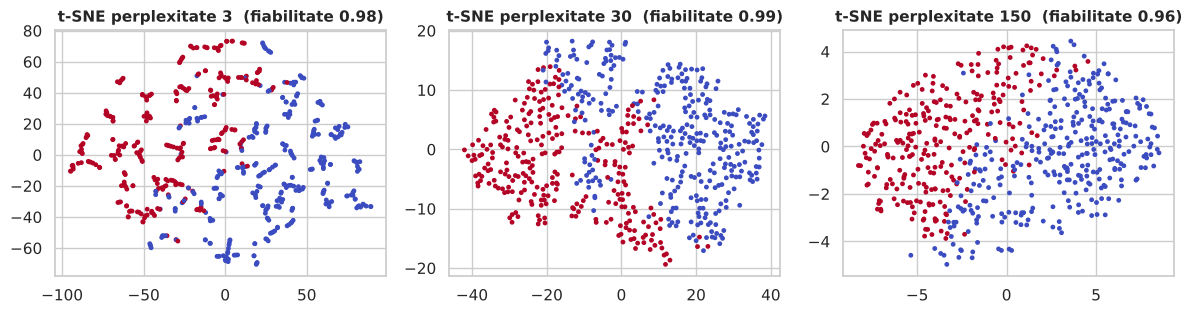

autoencoder 3 → 1 → 3, activare identity: RMSE de reconstrucție = 0.492


autoencoder 3 → 1 → 3, activare tanh    : RMSE de reconstrucție = 0.032
PCA cu 1 componentă                : RMSE de reconstrucție = 0.492


In [39]:
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neural_network import MLPRegressor

fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for a, perp in zip(ax, (3, 30, 150)):
    E = TSNE(2, perplexity=perp, random_state=0, init="pca").fit_transform(Z)
    a.scatter(*E.T, c=yd, s=6, cmap="coolwarm"); a.set_title(f"t-SNE perplexitate {perp}  (fiabilitate {trustworthiness(Z, E, n_neighbors=10):.2f})", fontsize=11)
plt.tight_layout(); plt.show()

th = np.random.default_rng(0).uniform(0, 1.5 * np.pi, 1500)                        # o structură curbă 1-D în 3-D (un arc care urcă)
S = StandardScaler().fit_transform(np.c_[np.cos(th), np.sin(th), 0.3 * th] + 0.02 * np.random.default_rng(1).normal(size=(1500, 3)))
for act in ("identity", "tanh"):
    ae = MLPRegressor(hidden_layer_sizes=(16, 1, 16), activation=act, solver="lbfgs", max_iter=2000, random_state=0).fit(S, S)
    print(f"autoencoder 3 → 1 → 3, activare {act:8s}: RMSE de reconstrucție = {np.sqrt(np.mean((ae.predict(S) - S)**2)):.3f}")
p1 = PCA(1).fit(S); print(f"PCA cu 1 componentă                : RMSE de reconstrucție = {np.sqrt(np.mean((p1.inverse_transform(p1.transform(S)) - S)**2)):.3f}")

Pentru o structură curbă 1-D, PCA poate folosi doar o dreaptă, la fel și un autoencoder *liniar*; un gât cu unități `tanh` urmărește curba (eroare de 15 ori mai mică). Pe datele *liniare* sintetice de la 5.1, modelul neliniar nu ar aduce niciun avantaj.

## 5.5 · Date reale — puteri pe benzi EEG

Nouă coloane numerice (`attention`, `meditation` și șapte benzi; `highGamma` este în mare parte artefact muscular). Puterile pe benzi sunt *asimetrice la dreapta pe mai multe ordine de mărime*: puține eșantioane cu putere uriașă domină varianța. Pipeline-ul de reducere este deci **log10 → standardizare → PCA**, iar numărul de componente se alege cu regulile de la 5.2.

ponderea PC1  brut+standardizat: 0.47    log10+standardizat: 0.52
componente pentru 90 % varianță  brut: 5    log10: 5
            PC1   PC2   PC3
delta      0.27 -0.40  0.71
theta      0.40 -0.33  0.17
lowAlpha   0.40  0.31  0.14
highAlpha  0.36 -0.04 -0.19
lowBeta    0.36  0.52  0.22
highBeta   0.40 -0.10 -0.37
lowGamma   0.34  0.34 -0.21
highGamma  0.26 -0.49 -0.42


acuratețea clasei majoritare    : 0.57
fold-uri contigue (oneste)     : {1: 0.49, 2: 0.45, 4: 0.42, 8: 0.46}
fold-uri amestecate (cu scurgere, prea bune): {1: 0.61, 2: 0.65, 4: 0.66, 8: 0.69}


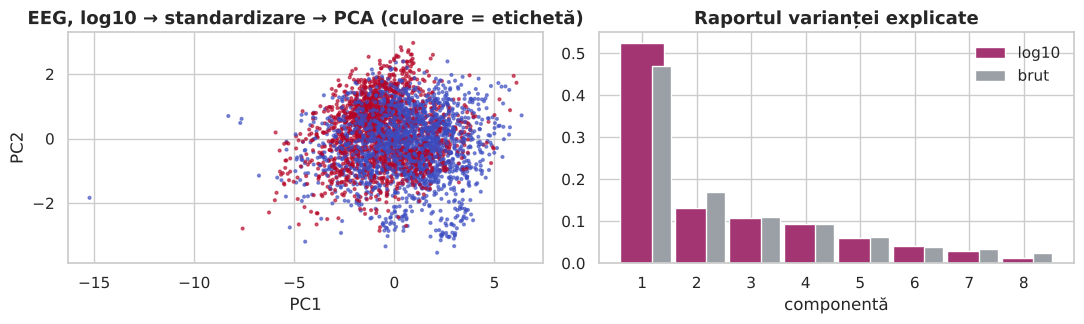

In [40]:
eeg = pd.read_csv("sleepy_driver_eeg_data.csv")
bands = ["delta", "theta", "lowAlpha", "highAlpha", "lowBeta", "highBeta", "lowGamma", "highGamma"]
yE = eeg["classification"].values
raw = eeg[bands]; lg = np.log10(raw)
pr = PCA().fit(StandardScaler().fit_transform(raw)); pl = PCA().fit(StandardScaler().fit_transform(lg))
print("ponderea PC1  brut+standardizat:", round(pr.explained_variance_ratio_[0], 2), "   log10+standardizat:", round(pl.explained_variance_ratio_[0], 2))
print("componente pentru 90 % varianță  brut:", int(np.searchsorted(np.cumsum(pr.explained_variance_ratio_), .9) + 1), "   log10:", int(np.searchsorted(np.cumsum(pl.explained_variance_ratio_), .9) + 1))
print(pd.DataFrame(pl.components_[:3].T, index=bands, columns=["PC1", "PC2", "PC3"]).round(2).to_string())

mk = lambda k: make_pipeline(StandardScaler(), PCA(n_components=k), LogisticRegression(max_iter=1000))
cvT = KFold(5, shuffle=False)                                    # fold-uri contigue: rândurile sunt o serie temporală
cvS = KFold(5, shuffle=True, random_state=0)                     # fold-uri amestecate: secundele vecine se scurg între antrenare și test
res_T = {k: round(float(cross_val_score(mk(k), lg, yE, cv=cvT).mean()), 2) for k in (1, 2, 4, 8)}
res_S = {k: round(float(cross_val_score(mk(k), lg, yE, cv=cvS).mean()), 2) for k in (1, 2, 4, 8)}
print("acuratețea clasei majoritare    :", round(max(yE.mean(), 1 - yE.mean()), 2))
print("fold-uri contigue (oneste)     :", res_T)
print("fold-uri amestecate (cu scurgere, prea bune):", res_S)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
Zl = PCA(2).fit_transform(StandardScaler().fit_transform(lg))
ax[0].scatter(*Zl.T, c=yE, s=4, cmap="coolwarm", alpha=0.6); ax[0].set(title="EEG, log10 → standardizare → PCA (culoare = etichetă)", xlabel="PC1", ylabel="PC2")
ax[1].bar(range(1, 9), pl.explained_variance_ratio_, color=PINK, label="log10"); ax[1].bar(np.arange(1, 9) + 0.35, pr.explained_variance_ratio_, width=0.35, color=GREY, label="brut"); ax[1].legend(); ax[1].set(title="Raportul varianței explicate", xlabel="componentă")
plt.tight_layout(); plt.show()

**Ce reținem din Partea 5.** (1) Scalați (și logaritmați datele asimetrice) înainte de PCA; (2) alegeți `k` după mai multe reguli și după eroarea de reconstrucție; (3) ajustați scalerele, selectorii și PCA **în interiorul** pipeline-ului de validare încrucișată; (4) folosiți t-SNE doar ca să priviți, niciodată ca să alimentați un model; (5) pe o serie temporală folosiți fold-uri **contigue**: fold-urile amestecate pun secunde vecine în antrenare și în test și raportează o acuratețe pe care sistemul nu o va atinge niciodată pe o cursă nouă – pe acest EEG acuratețea onestă este *sub* nivelul clasei majoritare, ceea ce este în sine o constatare importantă despre date.

# Partea 6 — Cum proiectăm un detector de puncte de schimbare

Un **punct de schimbare** (change point) este un moment în care *comportamentul statistic* al unei serii se schimbă: media, varianța, panta sau conținutul în frecvență. (Șoferul adoarme, o mașină pornește, începe un regim al unei clădiri.) Un detector răspunde la trei întrebări: **există o schimbare? unde? câte?** Orice metodă schimbă *alarmele false* pe *întârziere sau omisiuni* printr-un singur parametru. Lista de verificare a proiectării:

1. **Ce se schimbă?** media → cost `l2`; media și varianța → `normal`; orice → `rbf`/`kernel`; panta → eliminați mai întâi tendința sau diferențiați.
2. **Offline (seria întreagă este disponibilă) sau online (alarmă cât mai repede)?** Offline: PELT / segmentare binară. Online: CUSUM.
3. **Câte schimbări?** Cunoscut → `n_bkps`; necunoscut → **penalizare**.
4. **Cât de aproape de adevăr trebuie să fie locația?** → *marja* folosită la evaluare și `min_size`.
5. **Ce trebuie curățat mai întâi?** Valorile aberante creează schimbări false; la fel tendința și sezonalitatea.

## 6.1 · Semnale sintetice cu puncte de schimbare cunoscute

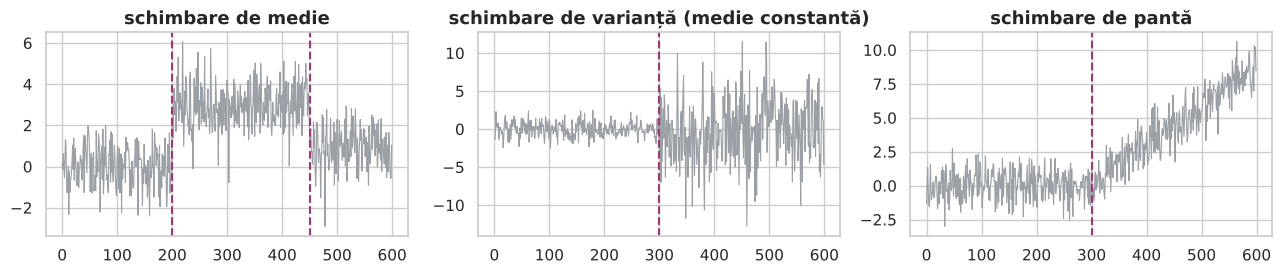

In [41]:
import ruptures as rpt
from ruptures.metrics import precision_recall
rng = np.random.default_rng(0)
n = 600
mean_shift = np.r_[rng.normal(0, 1, 200), rng.normal(3, 1, 250), rng.normal(1, 1, 150)]                 # schimbări la 200, 450
var_shift  = np.r_[rng.normal(0, 1, 300), rng.normal(0, 4, 300)]                                          # schimbare la 300 (media constantă!)
slope_shift = np.r_[np.arange(300) * 0.0, np.arange(300) * 0.03] + rng.normal(0, 1, 600)                  # panta începe la 300

fig, ax = plt.subplots(1, 3, figsize=(13, 2.9))
for a, v, ttl, cps in zip(ax, [mean_shift, var_shift, slope_shift], ["schimbare de medie", "schimbare de varianță (medie constantă)", "schimbare de pantă"], [[200, 450], [300], [300]]):
    a.plot(v, color=GREY, lw=0.8); a.set_title(ttl); [a.axvline(c, color=PINK, ls="--") for c in cps]
plt.tight_layout(); plt.show()

## 6.2 · CUSUM: cel mai simplu detector și cei doi parametri ai săi

**O singură schimbare, offline.** Suma cumulată a abaterilor de la media globală, `S_k = Σ (x_i − media)`, are forma unui *V sau Λ* care se întoarce la schimbare: locația este `argmax |S_k|`.

**CUSUM online** (alarmă în timp real) acumulează abaterea de la *media de referință* μ₀, minus o **derivă** `k` care face ca zgomotul mic să dispară: `g⁺_t = max(0, g⁺_{t−1} + (x_t − μ₀) − k)`, alarmă când `g⁺ > h`. Doi parametri, ambii în unități de σ:

* `k` (toleranța, de obicei **jumătate din saltul** pe care vreți să-l detectați: δ/2);
* `h` (pragul, de obicei 4–5σ): **h mai mare** → mai puține alarme false, dar o **întârziere mai lungă**.

estimare offline argmax|S|: 299 (adevăr 300)
h                1              3              5               8
k                                                               
0.25  alarmă falsă   alarmă falsă   alarmă falsă    întârziere 3
0.75  alarmă falsă   alarmă falsă   întârziere 7   întârziere 11
1.50  alarmă falsă  întârziere 15  întârziere 73  întârziere 123


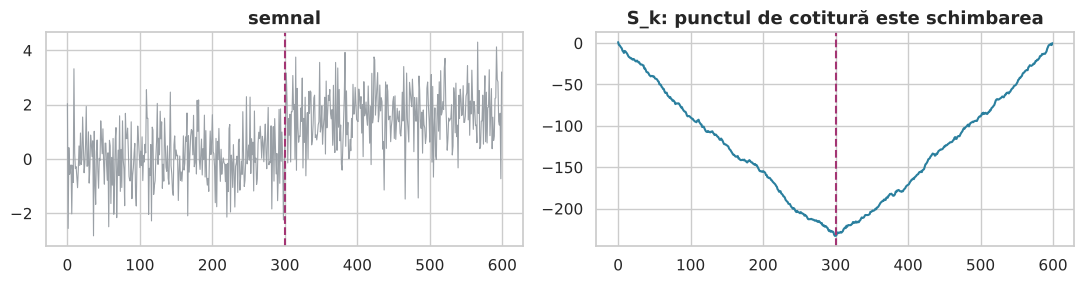

In [42]:
def cusum_alarms(x, mu0, sigma, k=0.5, h=5.0):
    "CUSUM bilateral; k și h în unități de sigma. Returnează indexul primei alarme (sau None)."
    gp = gm = 0.0
    for i, v in enumerate(x):
        z = (v - mu0) / sigma
        gp = max(0.0, gp + z - k); gm = max(0.0, gm - z - k)
        if gp > h or gm > h: return i
    return None

x1 = np.r_[np.random.default_rng(3).normal(0, 1, 300), np.random.default_rng(4).normal(1.5, 1, 300)]      # salt de 1.5 sigma la 300
S = np.cumsum(x1 - x1.mean()); print("estimare offline argmax|S|:", int(np.abs(S).argmax()), "(adevăr 300)")
rows = []
for k in (0.25, 0.75, 1.5):
    for h in (1, 3, 5, 8):
        a = cusum_alarms(x1, 0, 1, k, h); rows.append((k, h, a, "alarmă falsă" if a is not None and a < 300 else ("întârziere %d" % (a - 300) if a is not None else "ratat")))
print(pd.DataFrame(rows, columns=["k", "h", "prima alarmă", "rezultat"]).pivot(index="k", columns="h", values="rezultat").to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3)); ax[0].plot(x1, color=GREY, lw=0.8); ax[0].axvline(300, color=PINK, ls="--"); ax[0].set_title("semnal")
ax[1].plot(S, color=BLUE); ax[1].axvline(300, color=PINK, ls="--"); ax[1].set_title("S_k: punctul de cotitură este schimbarea"); plt.tight_layout(); plt.show()

**Citirea tabelului.** `h` mic (1) → alarme false înainte de schimbare; `h` mare → întârzierea crește; un `k` la fel de mare ca întregul salt (1.5 pentru un salt de 1.5σ) face detectorul lent (întârzieri de 73–123 de eșantioane), deoarece dovezile acumulate cresc doar cu `salt − k` pe eșantion. Proiectare tipică: `k = δ/2`, `h = 4–5`.

## 6.3 · Detecție offline cu `ruptures`: cost, metodă de căutare și penalizare

Biblioteca `ruptures` separă trei alegeri:

* **costul** (ce se schimbă): `"l2"` (media), `"normal"` (media și varianța), `"rbf"` (orice schimbare de distribuție), `"ar"` (dinamică autoregresivă);
* **metoda de căutare**: `Pelt` (exactă, numărul de schimbări **necunoscut**, folosește `pen`), `Binseg` (lacomă, `n_bkps` *sau* `pen`), `BottomUp`, `Window(width)`;
* **`pen`** – penalizarea per punct de schimbare (sau `n_bkps` când numărul este cunoscut) – cel mai important parametru: este prețul pe care un segment trebuie să-l plătească ca să existe. Regulă: **BIC**, `pen ≈ 2·σ²·ln(n)` pentru costul `l2`, cu σ estimat robust din primele diferențe: `σ = MAD(diff(x)) / (√2 · 0.6745)`. Apoi verificați **parcurgerea penalizării**: numărul de puncte de schimbare ar trebui să aibă un **platou** larg.

`predict` returnează *indexul de sfârșit al fiecărui segment*, deci ultimul element este întotdeauna `n` (lungimea); punctele de schimbare sunt celelalte. `min_size` interzice segmentele mai scurte; `jump` evaluează poziții candidate din `jump` în `jump` eșantioane (mai rapid, mai grosier).

sigma_hat = 0.97   BIC penalty = 11.9


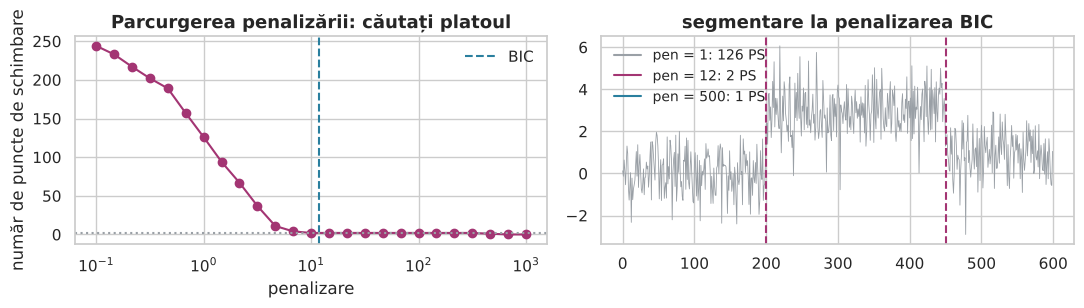

penalizări 0.1 / 1 / BIC / 100 / 1000 -> [244, 126, 2, 2, 0] puncte de schimbare; găsite: [200, 450]


In [43]:
def sigma_hat(v): d = np.diff(v); return np.median(np.abs(d - np.median(d))) / (np.sqrt(2) * 0.6745)
def cps(v, pen, model="l2", min_size=2, jump=1):
    return rpt.Pelt(model=model, min_size=min_size, jump=jump).fit(v).predict(pen=pen)[:-1]

s = sigma_hat(mean_shift); pen_bic = 2 * s**2 * np.log(len(mean_shift))
print(f"sigma_hat = {s:.2f}   BIC penalty = {pen_bic:.1f}")
pens = np.logspace(-1, 3, 25)
counts = [len(cps(mean_shift, p)) for p in pens]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].semilogx(pens, counts, "o-", color=PINK); ax[0].axvline(pen_bic, color=BLUE, ls="--", label="BIC"); ax[0].axhline(2, color=GREY, ls=":"); ax[0].legend(); ax[0].set(xlabel="penalizare", ylabel="număr de puncte de schimbare", title="Parcurgerea penalizării: căutați platoul")
for p_, c in [(1, GREY), (pen_bic, PINK), (500, BLUE)]:
    ax[1].plot([], [], color=c, label=f"pen = {p_:.0f}: {len(cps(mean_shift, p_))} PS")
ax[1].plot(mean_shift, color=GREY, lw=0.6)
for c in cps(mean_shift, pen_bic): ax[1].axvline(c, color=PINK, ls="--")
ax[1].legend(fontsize=10); ax[1].set_title("segmentare la penalizarea BIC")
plt.tight_layout(); plt.show()
print("penalizări 0.1 / 1 / BIC / 100 / 1000 ->", [len(cps(mean_shift, p)) for p in (0.1, 1, pen_bic, 100, 1000)], "puncte de schimbare; găsite:", cps(mean_shift, pen_bic))

## 6.4 · Costul trebuie să se potrivească schimbării

Semnalul cu *schimbare de varianță* are **media constantă**: costul `l2`, care presupune varianță constantă, raportează schimbări false ale mediei în jumătatea zgomotoasă; `normal` și `rbf` găsesc singura schimbare adevărată. `Binseg` cu `n_bkps` este instrumentul potrivit dacă *știți* câte schimbări există.

In [44]:
s_v = sigma_hat(var_shift)
print("schimbare de varianță, schimbarea adevărată la 300")
print("  l2 (doar media)    :", cps(var_shift, 2 * s_v**2 * np.log(600)), " <- fals: jumătatea zgomotoasă arată ca multe schimbări de medie")
print("  normal             :", cps(var_shift, 3 * np.log(600), model="normal", min_size=10))
print("  rbf                :", rpt.Pelt(model="rbf", min_size=10).fit(var_shift).predict(pen=5)[:-1])
print("  Binseg n_bkps=1, normal:", rpt.Binseg(model="normal", min_size=10).fit(var_shift).predict(n_bkps=1)[:-1])
sig_lin = np.c_[slope_shift, np.ones(600), np.arange(600)]                       # prima coloană = semnalul, celelalte = regresori (constantă, timp)
print("schimbare de pantă (adevărat 300): l2 ->", len(cps(slope_shift, 2 * np.log(600))), "trepte (o scară care aproximează rampa);  cost liniar ->", rpt.Pelt(model="linear", min_size=30).fit(sig_lin).predict(pen=25)[:-1])

schimbare de varianță, schimbarea adevărată la 300


  l2 (doar media)    : [318, 332, 334, 343, 345, 378, 381, 383, 439, 441, 446, 452, 459, 461, 474, 478, 485, 494, 496, 512, 556, 558, 591, 595]  <- fals: jumătatea zgomotoasă arată ca multe schimbări de medie


  normal             : [300]
  rbf                : [300]
  Binseg n_bkps=1, normal: [300]


schimbare de pantă (adevărat 300): l2 -> 7 trepte (o scară care aproximează rampa);  cost liniar -> [325]


O **schimbare de pantă** nu este o schimbare de medie: costul `l2` aproximează rampa cu o scară de trepte. Folosiți costul pentru regresie liniară pe porțiuni (`model="linear"`; prima coloană este semnalul, celelalte sunt regresori) – găsește o schimbare aproape de cea adevărată (estimarea este doar aproximativă, pentru că un cot nu este un salt) – sau, pentru un semnal foarte zgomotos, lucrați pe o primă diferență netezită (o schimbare de pantă devine o schimbare de medie), ca în exemplul cu biroul de mai jos.

## 6.5 · `min_size`, `jump` și marja de evaluare

`min_size` este cel mai scurt segment în care credeți. O rafală **mai scurtă decât `min_size` nu poate fi delimitată exact**: detectorul o observă totuși, dar trebuie să lărgească segmentul (vezi mai jos). `jump` = 5 evaluează fiecare a cincea poziție: de 5× mai rapid, eroare de locație de până la 5 eșantioane. Ca să **evaluați** un detector, numărați o schimbare prezisă drept corectă dacă se află într-o **marjă** de una adevărată (`ruptures.metrics.precision_recall`): marja este o alegere de proiectare legată de aplicație (secunde pentru o alarmă, zile pentru un regim).

In [45]:
burst = np.r_[rng.normal(0, 1, 250), rng.normal(5, 1, 6), rng.normal(0, 1, 344)]       # o rafală de 6 eșantioane la 250..255
for ms in (2, 5, 10, 20):
    print(f"min_size {ms:2d}: puncte de schimbare ->", cps(burst, 2 * np.log(600), min_size=ms))
true_cp = [200, 450, 600]; pred = cps(mean_shift, pen_bic, jump=5) + [600]
for margin in (1, 5, 20):
    p, r = precision_recall(true_cp, pred, margin=margin); print(f"marja {margin:2d}: precizie {p:.2f}  recall {r:.2f}")

min_size  2: puncte de schimbare -> [250, 256]


min_size  5: puncte de schimbare -> [250, 256]


min_size 10: puncte de schimbare -> [246, 256]


min_size 20: puncte de schimbare -> [239, 260]
marja  1: precizie 1.00  recall 1.00
marja  5: precizie 1.00  recall 1.00
marja 20: precizie 1.00  recall 1.00


## 6.6 · Mai întâi curățăm: valorile aberante creează puncte de schimbare false

Un vârf de electrod este un „segment” de 1 eșantion. Cu `min_size=1` detectorul îl raportează ca două puncte de schimbare; un pas robust de curățare (Hampel, Partea 4) sau un `min_size` mai mare le elimină.

In [46]:
spiky = mean_shift.copy(); spiky[[80, 320, 520]] += [25, -25, 25]
print("cu vârfuri, min_size 1 :", cps(spiky, pen_bic, min_size=1))
print("cu vârfuri, min_size 5 :", cps(spiky, pen_bic, min_size=5))
print("după Hampel + interpolare, min_size 1:", end=" ")
def hampel(s, window=11, n_sigmas=3, floor=0.0):
    s = pd.Series(s); med = s.rolling(window, center=True, min_periods=1).median(); mad = 1.4826 * (s - med).abs().rolling(window, center=True, min_periods=1).median()
    return ((s - med).abs() > n_sigmas * np.maximum(mad, floor)).values
clean = pd.Series(spiky).mask(hampel(spiky, 11, 4, 0.5)).interpolate().values; print(cps(clean, pen_bic, min_size=1))

cu vârfuri, min_size 1 : [80, 81, 200, 320, 321, 450, 520, 521]


cu vârfuri, min_size 5 : [77, 82, 200, 318, 323, 450, 516, 521]
după Hampel + interpolare, min_size 1: 

[200, 450]


## 6.7 · Date reale — EEG (somnolență etichetată) și biroul inteligent (program de lucru)

**EEG.** Fișierul are o etichetă `classification` care se schimbă de patru ori (rândurile 448, 933, 1748, 2863): un *pseudo-adevăr de referință*. Căutăm schimbări în **puterea delta logaritmică netezită**. Proiectare: log10 (date asimetrice) → **mediana fiecărui bloc de 30 s** (robustă, iar blocurile sunt aproape independente, deci formula pentru σ de zgomot alb se aplică; cu un netezitor *glisant* primele diferențe devin minuscule, σ este subestimat, iar penalizarea BIC prea mică – 43 de schimbări false) → `Pelt`, `l2`, de două ori penalizarea BIC (zgomotul nu este chiar alb) → indicii se transformă înapoi în secunde.

**Biroul inteligent.** Nivelul de CO₂ al unui birou își schimbă regimul când oamenii sosesc și pleacă. Adevărul este în coloana `occupancy`: unde trece de la 0 la > 0 și înapoi. Detectăm doar din CO₂. CO₂ nu face un salt când sosesc oamenii, ci *urcă în rampă*, deci un model de salt al mediei pe nivel dă o scară de trepte; folosim mediane pe blocuri de 15 minute și apoi **prima diferență** (o rampă devine un salt de medie).

EEG  schimbări reale ale etichetei: [448, 933, 1748, 2863] 
     detectate (secunde)         : [210, 420, 840, 2340, 2850]
     precizie 0.60 recall 0.75 cu o marjă de 150 s



Birou  începuturi/sfârșituri ale ocupării (index minut): [407, 1065, 1909, 2505, 3288, 3945, 4727, 5385, 6169, 6825]
       detectate din CO2                    : [420, 600, 780, 1050, 1230, 1935, 2115, 2490, 2670, 3315, 3495, 3675, 3930, 4110, 4740, 4920, 5100, 5370, 5550, 6180, 6360, 6540, 6810, 6990]
        precizie 0.42 recall 1.00 cu o marjă de 90 min (detecțiile în plus sunt pauza de prânz)


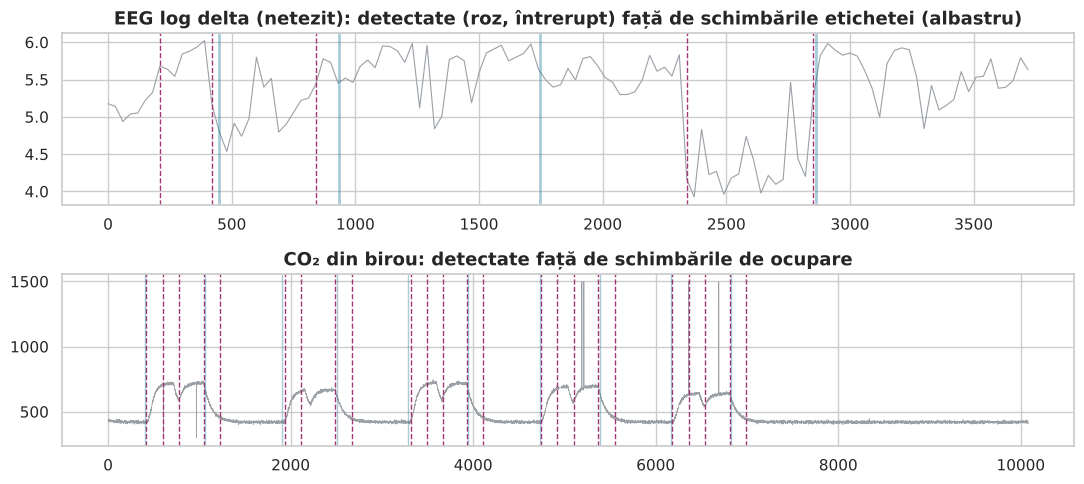

In [47]:
eeg = pd.read_csv("sleepy_driver_eeg_data.csv")
B = 30                                                                      # bloc de 30 s: mediana fiecărui bloc este robustă, iar blocurile sunt aproape independente
ld = np.log10(eeg["delta"]).groupby(np.arange(len(eeg)) // B).median().values
s_e = sigma_hat(ld); pen_e = 2 * (2 * s_e**2 * np.log(len(ld)))               # de două ori penalizarea BIC (zgomotul real nu este alb)
cp_e = (np.array(cps(ld, pen_e, min_size=2)) * B).tolist()
true_e = [int(v) for v in np.flatnonzero(np.diff(eeg.classification.values)) + 1]
print("EEG  schimbări reale ale etichetei:", true_e, "\n     detectate (secunde)         :", cp_e)
p, r = precision_recall(true_e + [len(eeg)], cp_e + [len(eeg)], margin=150); print(f"     precizie {p:.2f} recall {r:.2f} cu o marjă de 150 s")

off = pd.read_csv("smart_office_dataset.csv", parse_dates=["timestamp"], index_col="timestamp")
co2 = off.co2_ppm.interpolate().clip(300, 1500)
B2 = 15                                                                      # mediane pe blocuri de 15 minute, apoi prima diferență: rampele devin salturi de medie
d_o = np.diff(co2.groupby(np.arange(len(co2)) // B2).median().values)
s_o = sigma_hat(d_o); cp_o = ((np.array(cps(d_o, 2 * s_o**2 * np.log(len(d_o)), min_size=12)) + 1) * B2)
occ = (off.occupancy.rolling(30, center=True, min_periods=1).max() > 0).astype(int).values; true_o = np.flatnonzero(np.diff(occ)) + 1
print("\nBirou  începuturi/sfârșituri ale ocupării (index minut):", true_o.tolist())
print("       detectate din CO2                    :", cp_o.tolist())
p, r = precision_recall(true_o.tolist() + [len(co2)], cp_o.tolist() + [len(co2)], margin=90); print(f"        precizie {p:.2f} recall {r:.2f} cu o marjă de 90 min (detecțiile în plus sunt pauza de prânz)")
fig, ax = plt.subplots(2, 1, figsize=(11, 5))
ax[0].plot(np.arange(len(ld)) * B, ld, color=GREY, lw=0.8)
[ax[0].axvline(c, color=PINK, ls="--", lw=1) for c in cp_e]; [ax[0].axvline(c, color=BLUE, lw=2, alpha=0.4) for c in true_e]; ax[0].set_title("EEG log delta (netezit): detectate (roz, întrerupt) față de schimbările etichetei (albastru)")
ax[1].plot(co2.values, color=GREY, lw=0.5); [ax[1].axvline(c, color=PINK, ls="--", lw=1) for c in cp_o]; [ax[1].axvline(c, color=BLUE, lw=1, alpha=0.4) for c in true_o]; ax[1].set_title("CO₂ din birou: detectate față de schimbările de ocupare")
plt.tight_layout(); plt.show()

**Ce reținem din Partea 6.** Penalizarea (sau `h` la CUSUM) este butonul pentru alarme false și trebuie aleasă cu un platou/o parcurgere și o estimare a zgomotului; costul trebuie să se potrivească cu ce se schimbă; curățați întâi valorile aberante și tendința; evaluați cu o marjă care are sens în aplicație. O etichetă reală precum „somnolent” nu este neapărat o schimbare *statistică* a unui singur semnal – detectorul va găsi schimbările care sunt în date, iar voi trebuie să spuneți care dintre ele concordă cu eticheta.

# Partea 7 — Punem pașii în ordine: un pipeline complet de pre-procesare

Metodele din Părțile 1–6 nu sunt independente; **ordinea** contează, iar fiecare pas are parametri care trebuie notați și justificați. O ordine fiabilă pentru o serie temporală de senzor:

1. **Grilă regulată** – reindexați la perioada de eșantionare; faceți golurile vizibile.
2. **Reguli fizice** – valorile din afara domeniului fizic devin `NaN` (înainte de orice statistică).
3. **Valori aberante** – detector robust, glisant (Hampel); valorile detectate devin `NaN`.
4. **Interpolare** – doar goluri scurte (`limit`), cele mai lungi rămân `NaN` și sunt *marcate*.
5. **Eliminarea zgomotului** – trece-jos / median / Savitzky–Golay.
6. **Eliminarea tendinței / sezonalității** – doar dacă pasul următor cere staționaritate.
7. **Reducerea dimensionalității / trăsături** – scaler și PCA ajustate doar pe partea de antrenare.
8. **Puncte de schimbare / modelare.**

## 7.1 · De ce eliminăm zgomotul *după* ce scoatem valorile aberante

Un filtru trece-jos împrăștie fiecare vârf peste vecinii săi (energia vârfului devine o umflătură netedă pe care niciun detector nu o mai recunoaște ca valoare aberantă). Testăm pe o copie curățată a CO₂ din birou, în care plantăm 10 vârfuri, astfel încât adevărul să fie cunoscut.

In [48]:
def hampel(s, window=11, n_sigmas=3, floor=0.0):
    s = pd.Series(s); med = s.rolling(window, center=True, min_periods=1).median(); mad = 1.4826 * (s - med).abs().rolling(window, center=True, min_periods=1).median()
    return ((s - med).abs() > n_sigmas * np.maximum(mad, floor)).values

off = pd.read_csv("smart_office_dataset.csv", parse_dates=["timestamp"], index_col="timestamp")
co2 = off.co2_ppm.copy()
co2[(co2 < 300) | (co2 > 1500)] = np.nan
ref = co2.interpolate()                                           # „adevărul” pentru acest experiment
rng = np.random.default_rng(0)
pos = rng.choice(np.arange(100, len(ref) - 100), 10, replace=False)
noisy = ref.copy(); noisy.iloc[pos] += rng.choice([-1, 1], 10) * 400

sos = signal.butter(4, 1/10, btype="low", fs=1.0, output="sos")   # frecvență de tăiere 1/10 cicluri pe minut
A = pd.Series(signal.sosfiltfilt(sos, noisy.values), index=noisy.index)                                  # A: mai întâi filtrul
fl = hampel(A, 15, 5, 8); A2 = A.mask(fl).interpolate()                                                   #    apoi Hampel
fl = hampel(noisy, 15, 5, 8); Bp = noisy.mask(fl).interpolate(); B2 = pd.Series(signal.sosfiltfilt(sos, Bp.values), index=noisy.index)   # B: mai întâi Hampel, apoi filtrul
ref_f = pd.Series(signal.sosfiltfilt(sos, ref.values), index=ref.index)
rm = lambda a: float(np.sqrt(np.mean((a.values - ref_f.values) ** 2)))
print(f"RMSE față de adevărul filtrat   fără curățare: {rm(pd.Series(signal.sosfiltfilt(sos, noisy.values), index=noisy.index)):6.2f}   filtru→Hampel: {rm(A2):6.2f}   Hampel→filtru: {rm(B2):6.2f}")

RMSE față de adevărul filtrat   fără curățare:   5.35   filtru→Hampel:   5.35   Hampel→filtru:   0.13


## 7.2 · O funcție de pipeline cu un jurnal al deciziilor

Fiecare decizie devine un *parametru* al unei singure funcții, iar fiecare efect un *număr* într-un raport: câte valori au fost eliminate, câte interpolate, câte rămân lipsă. Aceasta este ceea ce predați și apărați.

lipsă_la_început                31
eliminate_de_limitele_fizice     6
eliminate_de_Hampel              0
interpolate                     37
încă_lipsă (gol > max_gap)       0


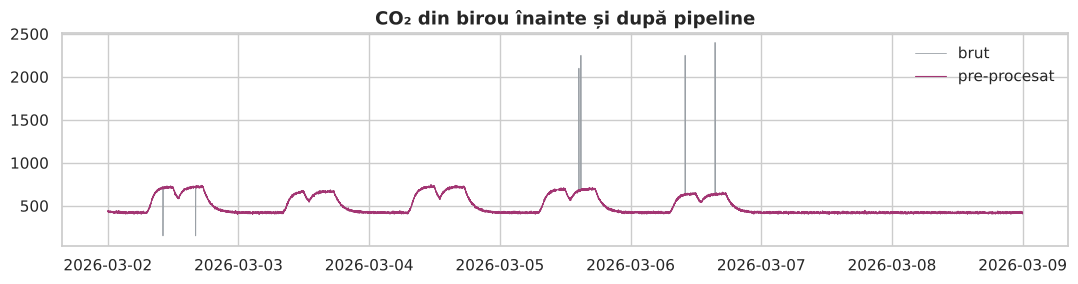

In [49]:
def preprocess(s, freq, lo, hi, hampel_window, hampel_sigma, floor, max_gap, lp_cut=None, fs=None):
    "Grilă regulată -> limite fizice -> Hampel -> interpolarea golurilor scurte -> trece-jos opțional. Returnează (serie curată, dicționar-raport)."
    rep = {}
    s = s.copy(); s.index = pd.DatetimeIndex(s.index)
    s = s.reindex(pd.date_range(s.index[0], s.index[-1], freq=freq)); rep["lipsă_la_început"] = int(s.isna().sum())
    bad = (s < lo) | (s > hi); s[bad] = np.nan; rep["eliminate_de_limitele_fizice"] = int(bad.sum())
    fl = hampel(s.interpolate(limit_area="inside"), hampel_window, hampel_sigma, floor) & s.notna().values; s[fl] = np.nan; rep["eliminate_de_Hampel"] = int(fl.sum())
    n_before = int(s.isna().sum()); s = s.interpolate("time", limit=max_gap, limit_area="inside"); rep["interpolate"] = n_before - int(s.isna().sum())
    rep["încă_lipsă (gol > max_gap)"] = int(s.isna().sum())
    if lp_cut:
        ok = s.notna(); y = s.copy(); y[ok] = signal.sosfiltfilt(signal.butter(4, lp_cut, fs=fs, output="sos"), s.ffill().bfill().values)[ok.values]; s = y
    return s, rep

clean_co2, rep = preprocess(off.co2_ppm, "1min", lo=300, hi=1500, hampel_window=15, hampel_sigma=5, floor=8, max_gap=60)
print(pd.Series(rep).to_string())
fig, ax = plt.subplots(figsize=(11, 3)); ax.plot(off.co2_ppm, color=GREY, lw=0.6, label="brut"); ax.plot(clean_co2, color=PINK, lw=0.8, label="pre-procesat"); ax.legend(); ax.set_title("CO₂ din birou înainte și după pipeline")
plt.tight_layout(); plt.show()

**Tabel de justificare (șablon pentru raportul vostru).** Un rând pe pas, trei coloane pe care un cititor le poate verifica:

| Pas | Parametri și valoare | De ce această valoare (dovezi) |
|---|---|---|
| limite fizice | 300–1500 ppm | CO₂ exterior ≈ 420 ppm; 1500 ppm înseamnă calitate slabă a aerului, > 2000 nu este credibil cu ≤ 12 persoane |
| Hampel | fereastră 15, 5σ, prag minim 8 ppm | vârfurile durează 1–2 eșantioane; zgomotul senzorului este de câțiva ppm; un prag minim de 3 a dat 14 alarme false |
| interpolare | liniară în timp, `limit` 60 min | golurile de 31 min sunt mai scurte decât scala de timp de 2 ore a schimbărilor de CO₂ |
| trece-jos (opțional) | Butterworth de ordin 4, 0.1 cicluri/min | elimină zgomotul peste scala de 10 minute; fază zero pentru că analiza este offline |

## 7.3 · Același pipeline pe datele de trafic

Alte date, alți parametri: eșantionare orară, sezonalitate săptămânală, valori fizic imposibile există în *alte* coloane (o temperatură de 0 K, 9831 mm de ploaie), dar seria pe care o procesăm, `traffic_volume`, are nevoie doar de domeniul 0–8000 și de un detector robust care **nu** trebuie să marcheze extremele reale din orele de vârf: pasul Hampel nu elimină deci nimic aici, ceea ce este rezultatul corect.

In [50]:
tr = pd.read_csv("Metro_Interstate_Traffic_Volume.csv", parse_dates=["date_time"]).drop_duplicates("date_time").set_index("date_time")
v17 = tr.loc["2017", "traffic_volume"]
clean_tr, rep_tr = preprocess(v17, "1h", lo=0, hi=8000, hampel_window=25, hampel_sigma=6, floor=300, max_gap=6)
print(pd.Series(rep_tr).to_string())
print("cel mai lung gol rămas (h):",
      int(clean_tr.isna().astype(int).groupby(clean_tr.notna().cumsum()).sum().max()))

lipsă_la_început                47
eliminate_de_limitele_fizice     0
eliminate_de_Hampel              0
interpolate                     43
încă_lipsă (gol > max_gap)       4
cel mai lung gol rămas (h): 3


**Ce reținem din Partea 7.** Un pipeline este un *lanț de decizii*. Ordinea este fixată de logică (nu putem netezi înainte să scoatem valorile aberante, nu putem detecta puncte de schimbare înainte să tratăm nivelul și sezonalitatea), parametrii de dovezi (spectru, lungimi de goluri, teste cu valori aberante plantate, validare), iar totul este consemnat într-un jurnal.

Continuați acum cu `Lab4_Exercitii.ipynb`.